# Wavelet-Based Image Denoising and Enhancement


## 4.3 2D Wavelet Transform

### 4.3.2 Code Example: Visualizing Subbands

In [ ]:
import pywt
import matplotlib.pyplot as plt
import numpy as np
from skimage import data, img_as_float

# Load and prepare grayscale image
image = img_as_float(data.camera())
print(f"Original image shape: {image.shape}")

# Apply single-level 2D DWT
coeffs2 = pywt.dwt2(image, 'db4')  # Daubechies-4 wavelet
LL, (LH, HL, HH) = coeffs2

# Display original image and subbands
fig, axes = plt.subplots(2, 3, figsize=(15, 10))

# Original image
axes[0, 0].imshow(image, cmap='gray')
axes[0, 0].set_title('Original Image', fontsize=12, fontweight='bold')
axes[0, 0].axis('off')

# Remove empty subplot
axes[0, 1].axis('off')
axes[0, 2].axis('off')

# Subbands
subbands = [LL, LH, HL, HH]
titles = ['Approximation (LL)', 'Horizontal Detail (LH)', 
          'Vertical Detail (HL)', 'Diagonal Detail (HH)']
positions = [(1, 0), (1, 1), (1, 2), (0, 1)]

for i, (subband, title, (row, col)) in enumerate(zip(subbands, titles, positions)):
    if i == 0:  # LL subband
        axes[row, col].imshow(subband, cmap='gray')
    else:  # Detail subbands
        # Use different colormap for better visualization of details
        axes[row, col].imshow(subband, cmap='RdBu_r')
    
    axes[row, col].set_title(title, fontsize=10)
    axes[row, col].axis('off')
    
    # Add subband statistics
    mean_val = np.mean(np.abs(subband))
    std_val = np.std(subband)
    axes[row, col].text(0.02, 0.98, f'Mean: {mean_val:.3f}\nStd: {std_val:.3f}', 
                       transform=axes[row, col].transAxes, fontsize=8,
                       verticalalignment='top', bbox=dict(boxstyle='round', 
                       facecolor='white', alpha=0.8))

plt.tight_layout()
plt.savefig('./output/image_denoising.png', dpi=300)
plt.show()

# Print coefficient statistics
print("\nSubband Statistics:")
for name, coeff in zip(['LL', 'LH', 'HL', 'HH'], [LL, LH, HL, HH]):
    print(f"{name}: Shape={coeff.shape}, Mean={np.mean(np.abs(coeff)):.4f}, "
          f"Std={np.std(coeff):.4f}, Max={np.max(np.abs(coeff)):.4f}")

## 4.4 Dataset Examples and Loading

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 11s 0us/step
downloading Olivetti faces from https://ndownloader.figshare.com/files/5976027 to C:\Users\shouk\scikit_learn_data


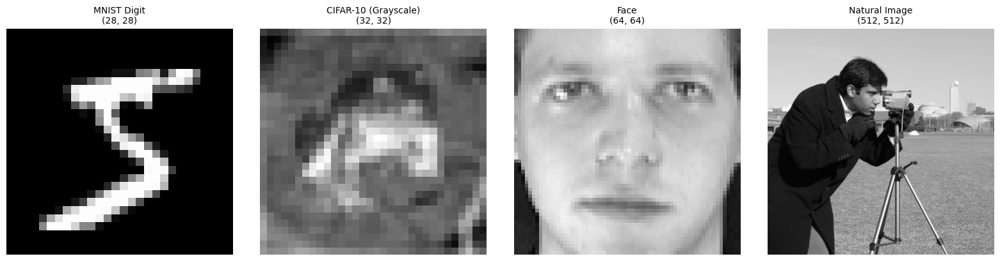

In [ ]:
import tensorflow as tf
import tensorflow_datasets as tfds
from sklearn.datasets import fetch_olivetti_faces
import requests
from PIL import Image
import io

def load_dataset_examples():
    """Load examples from different image datasets"""
    
    # 1. MNIST digit
    (x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()
    mnist_sample = x_train[0].astype(np.float32) / 255.0
    
    # 2. CIFAR-10 (convert to grayscale)
    (x_cifar, y_cifar), _ = tf.keras.datasets.cifar10.load_data()
    cifar_sample = np.mean(x_cifar[0], axis=2).astype(np.float32) / 255.0
    
    # 3. Face dataset
    faces = fetch_olivetti_faces()
    face_sample = faces.images[0]
    
    # 4. Natural image (from skimage)
    natural_sample = img_as_float(data.camera())
    
    return {
        'MNIST Digit': mnist_sample,
        'CIFAR-10 (Grayscale)': cifar_sample,
        'Face': face_sample,
        'Natural Image': natural_sample
    }

# Load and display dataset examples
datasets = load_dataset_examples()

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for i, (name, img) in enumerate(datasets.items()):
    axes[i].imshow(img, cmap='gray')
    axes[i].set_title(f'{name}\n{img.shape}', fontsize=10)
    axes[i].axis('off')

plt.tight_layout()
plt.savefig('./output/dataset_examples.png', dpi=300)  
plt.show()

## 4.5 Removing Gaussian Noise


### 4.5.1 Enhanced Gaussian Noise Removal with Evaluation


Image shape: (512, 512)


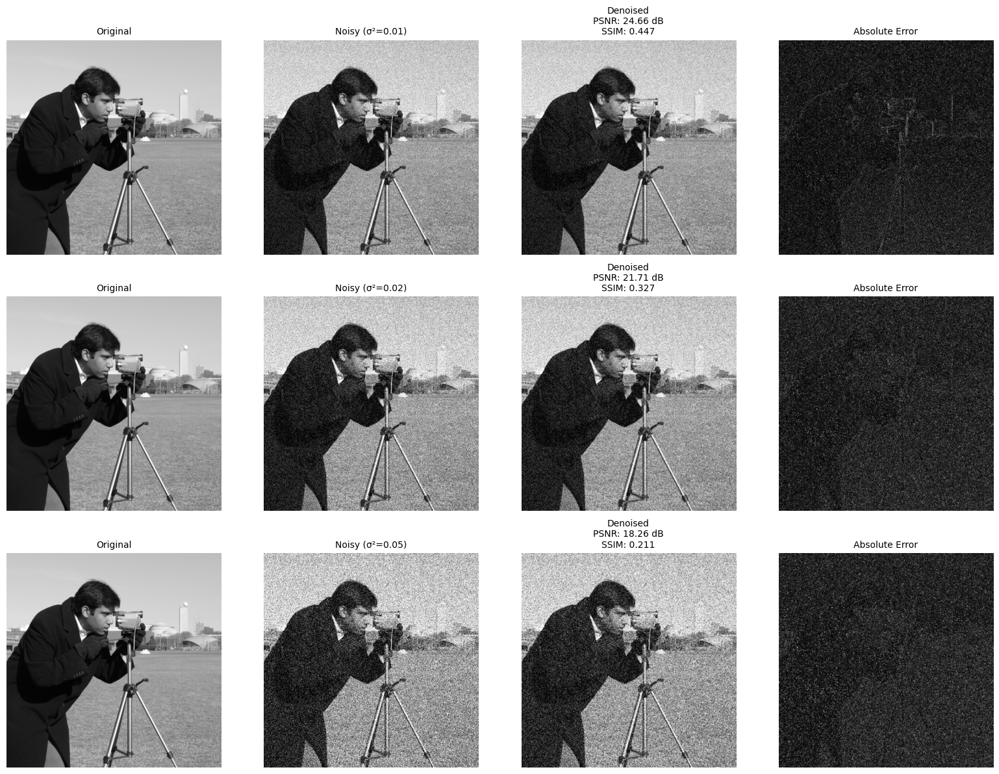


Denoising Performance Summary:

Noise Var 0.01:
  PSNR: 24.66 dB
  SSIM: 0.4473
  MSE: 0.0034
  Correlation: 0.9794
  PSNR_Improvement: 4.23 dB
  SSIM_Improvement: 0.1509

Noise Var 0.02:
  PSNR: 21.71 dB
  SSIM: 0.3271
  MSE: 0.0067
  Correlation: 0.9594
  PSNR_Improvement: 4.03 dB
  SSIM_Improvement: 0.1162

Noise Var 0.05:
  PSNR: 18.26 dB
  SSIM: 0.2110
  MSE: 0.0149
  Correlation: 0.9087
  PSNR_Improvement: 4.04 dB
  SSIM_Improvement: 0.0830


In [ ]:
import pywt
import numpy as np
import matplotlib.pyplot as plt
from skimage import data, img_as_float
from skimage.util import random_noise
from skimage.metrics import peak_signal_noise_ratio, structural_similarity
from scipy.stats import pearsonr

def evaluate_denoising(original, denoised, noisy=None):
    """Comprehensive evaluation of denoising performance"""
    metrics = {}
    
    # PSNR (Peak Signal-to-Noise Ratio)
    metrics['PSNR'] = peak_signal_noise_ratio(original, denoised, data_range=1.0)
    
    # SSIM (Structural Similarity Index)
    metrics['SSIM'] = structural_similarity(original, denoised, data_range=1.0)
    
    # MSE (Mean Squared Error)
    metrics['MSE'] = np.mean((original - denoised) ** 2)
    
    # Correlation coefficient
    metrics['Correlation'] = pearsonr(original.flatten(), denoised.flatten())[0]
    
    if noisy is not None:
        # Improvement metrics
        metrics['PSNR_Improvement'] = peak_signal_noise_ratio(original, denoised, data_range=1.0) - \
                                    peak_signal_noise_ratio(original, noisy, data_range=1.0)
        metrics['SSIM_Improvement'] = structural_similarity(original, denoised, data_range=1.0) - \
                                    structural_similarity(original, noisy, data_range=1.0)
    
    return metrics

def soft_threshold_adaptive(coeffs, sigma_noise, method='bayes'):
    """Apply adaptive thresholding to wavelet coefficients"""
    if method == 'bayes':
        # BayesShrink threshold estimation
        sigma_y = np.std(coeffs)
        if sigma_y > sigma_noise:
            sigma_x = np.sqrt(sigma_y**2 - sigma_noise**2)
            threshold = sigma_noise**2 / sigma_x
        else:
            threshold = sigma_y
    elif method == 'sure':
        # SURE threshold (simplified)
        n = coeffs.size
        threshold = sigma_noise * np.sqrt(2 * np.log(n))
    else:
        # Universal threshold
        n = coeffs.size
        threshold = sigma_noise * np.sqrt(2 * np.log(n))
    
    return pywt.threshold(coeffs, threshold, mode='soft')

# Set random seed for reproducibility
np.random.seed(42)

# Load and prepare image
image = img_as_float(data.camera())
print(f"Image shape: {image.shape}")

# Add different levels of Gaussian noise
noise_levels = [0.01, 0.02, 0.05]
results = {}

fig, axes = plt.subplots(len(noise_levels), 4, figsize=(16, 12))
if len(noise_levels) == 1:
    axes = axes.reshape(1, -1)

for i, noise_var in enumerate(noise_levels):
    # Add Gaussian noise - use numpy's random number generator
    rng = np.random.default_rng(42)  # Create a random state for reproducibility
    noisy = random_noise(image, mode='gaussian', var=noise_var, rng=rng)
    sigma_noise = np.sqrt(noise_var)
    
    # Simple thresholding approach
    coeffs = pywt.dwt2(noisy, 'db8')
    LL, (LH, HL, HH) = coeffs
    
    # Apply soft thresholding with adaptive threshold
    LH_thresh = soft_threshold_adaptive(LH, sigma_noise, method='bayes')
    HL_thresh = soft_threshold_adaptive(HL, sigma_noise, method='bayes')
    HH_thresh = soft_threshold_adaptive(HH, sigma_noise, method='bayes')
    
    # Reconstruct
    denoised = pywt.idwt2((LL, (LH_thresh, HL_thresh, HH_thresh)), 'db8')
    
    # Clip to valid range
    denoised = np.clip(denoised, 0, 1)
    
    # Evaluate
    metrics = evaluate_denoising(image, denoised, noisy)
    results[f'noise_var_{noise_var}'] = metrics
    
    # Plot results
    images = [image, noisy, denoised, np.abs(image - denoised)]
    titles = ['Original', f'Noisy (σ²={noise_var})', 
              f'Denoised\nPSNR: {metrics["PSNR"]:.2f} dB\nSSIM: {metrics["SSIM"]:.3f}',
              'Absolute Error']
    
    for j, (img, title) in enumerate(zip(images, titles)):
        axes[i, j].imshow(img, cmap='gray')
        axes[i, j].set_title(title, fontsize=10)
        axes[i, j].axis('off')

plt.tight_layout()
plt.savefig('./output/denoising_results.png', dpi=300)
plt.show()

# Print detailed results
print("\nDenoising Performance Summary:")
print("=" * 60)
for noise_level, metrics in results.items():
    print(f"\n{noise_level.replace('_', ' ').title()}:")
    for metric, value in metrics.items():
        if 'PSNR' in metric:
            print(f"  {metric}: {value:.2f} dB")
        else:
            print(f"  {metric}: {value:.4f}")

## 4.6 Feature Enhancement

### 4.6.1 Enhanced Feature Enhancement with Multiple Techniques

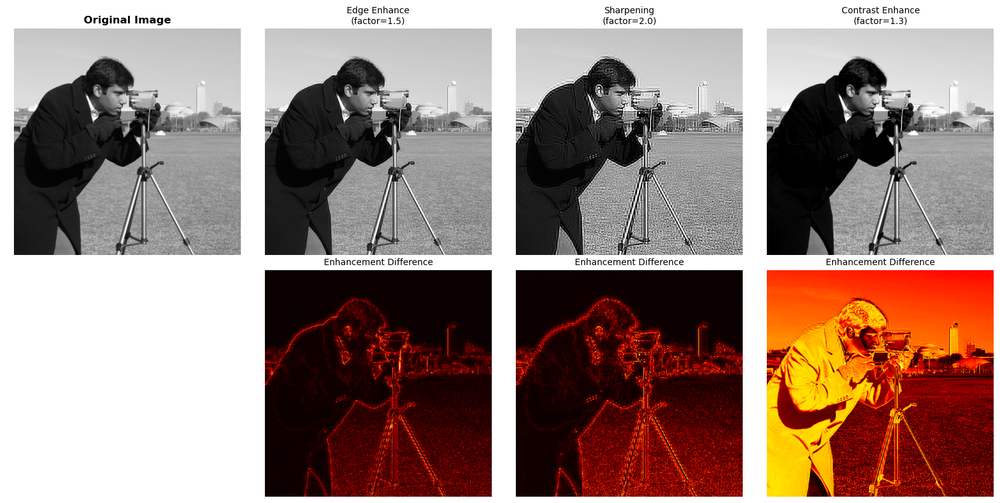

Enhancement Analysis:
Edge Enhance:
  Enhancement ratio: 1.37
  Mean intensity: 0.506
  Std deviation: 0.293

Sharpening:
  Enhancement ratio: 2.97
  Mean intensity: 0.506
  Std deviation: 0.315

Contrast Enhance:
  Enhancement ratio: 1.21
  Mean intensity: 0.508
  Std deviation: 0.339



In [ ]:
def enhance_image_features(image, method='edge_enhance', factor=1.5):
    """Apply various feature enhancement techniques using wavelets"""
    
    # Apply 2-level DWT for better feature separation
    coeffs = pywt.wavedec2(image, 'db8', level=2)
    
    if method == 'edge_enhance':
        # Amplify high-frequency details
        coeffs_enhanced = [coeffs[0]]  # Keep approximation unchanged
        for level_details in coeffs[1:]:
            enhanced_details = tuple(detail * factor for detail in level_details)
            coeffs_enhanced.append(enhanced_details)
            
    elif method == 'sharpening':
        # More aggressive sharpening - amplify finest details more
        coeffs_enhanced = [coeffs[0]]
        for i, level_details in enumerate(coeffs[1:]):
            level_factor = factor * (2 - i * 0.3)  # Decrease factor for coarser levels
            enhanced_details = tuple(detail * level_factor for detail in level_details)
            coeffs_enhanced.append(enhanced_details)
            
    elif method == 'contrast_enhance':
        # Enhance contrast by modifying approximation and details
        cA = coeffs[0]
        # Histogram equalization on approximation
        cA_enhanced = (cA - np.mean(cA)) * 1.2 + np.mean(cA)
        coeffs_enhanced = [cA_enhanced]
        
        for level_details in coeffs[1:]:
            enhanced_details = tuple(detail * factor for detail in level_details)
            coeffs_enhanced.append(enhanced_details)
    
    # Reconstruct enhanced image
    enhanced = pywt.waverec2(coeffs_enhanced, 'db8')
    return np.clip(enhanced, 0, 1)

# Load test image
image = img_as_float(data.camera())

# Apply different enhancement methods
methods = ['edge_enhance', 'sharpening', 'contrast_enhance']
factors = [1.5, 2.0, 1.3]

fig, axes = plt.subplots(2, len(methods) + 1, figsize=(16, 8))

# Original image
axes[0, 0].imshow(image, cmap='gray')
axes[0, 0].set_title('Original Image', fontweight='bold')
axes[0, 0].axis('off')
axes[1, 0].axis('off')  # Empty subplot

for i, (method, factor) in enumerate(zip(methods, factors)):
    enhanced = enhance_image_features(image, method=method, factor=factor)
    
    # Enhanced image
    axes[0, i+1].imshow(enhanced, cmap='gray')
    axes[0, i+1].set_title(f'{method.replace("_", " ").title()}\n(factor={factor})', 
                          fontsize=10)
    axes[0, i+1].axis('off')
    
    # Difference image to show enhancement
    diff = np.abs(enhanced - image)
    axes[1, i+1].imshow(diff, cmap='hot')
    axes[1, i+1].set_title('Enhancement Difference', fontsize=10)
    axes[1, i+1].axis('off')

plt.tight_layout()
plt.savefig('./output/feature_enhancement.png', dpi=300)
plt.show()

# Quantitative analysis of enhancement
print("Enhancement Analysis:")
print("=" * 40)
for method, factor in zip(methods, factors):
    enhanced = enhance_image_features(image, method=method, factor=factor)
    
    # Calculate edge strength (using Sobel operator approximation)
    gy, gx = np.gradient(enhanced)
    edge_strength = np.mean(np.sqrt(gx**2 + gy**2))
    
    orig_gy, orig_gx = np.gradient(image)
    orig_edge_strength = np.mean(np.sqrt(orig_gx**2 + orig_gy**2))
    
    enhancement_ratio = edge_strength / orig_edge_strength
    
    print(f"{method.replace('_', ' ').title()}:")
    print(f"  Enhancement ratio: {enhancement_ratio:.2f}")
    print(f"  Mean intensity: {np.mean(enhanced):.3f}")
    print(f"  Std deviation: {np.std(enhanced):.3f}")
    print()


## 4.7 Multi-Level Decomposition

### 4.7.1 Comprehensive Multi-Level Denoising Analysis

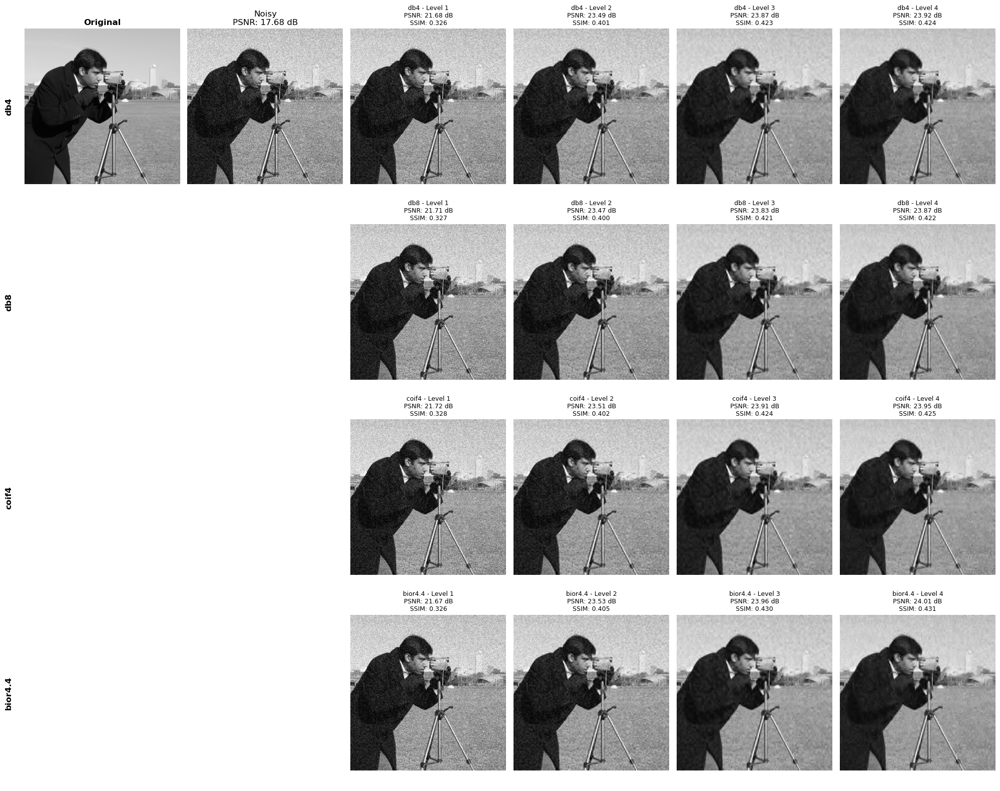

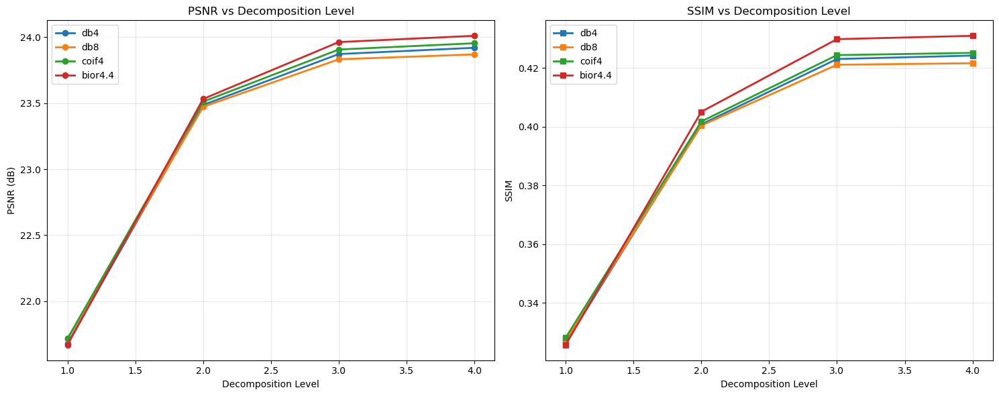

Best Performing Wavelet-Level Combinations:
Best PSNR: 24.010 dB (bior4.4 - level_4)
Best SSIM: 0.4310 (bior4.4 - level_4)


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pywt
from skimage import data
from skimage.util import img_as_float, random_noise
from skimage.metrics import peak_signal_noise_ratio, structural_similarity

def comprehensive_wavelet_analysis(image, wavelets=['db4', 'db8', 'coif4', 'bior4.4'], 
                                 max_levels=4):
    """Analyze denoising performance across different wavelets and levels"""
    
    # Add controlled noise with proper random number generator
    noisy = random_noise(image, mode='gaussian', var=0.02, rng=42)
    
    results = {}
    
    fig, axes = plt.subplots(len(wavelets), max_levels + 2, figsize=(20, 16))
    
    for i, wavelet in enumerate(wavelets):
        results[wavelet] = {}
        
        # Original and noisy (first two columns)
        if i == 0:  # Only show once
            axes[i, 0].imshow(image, cmap='gray')
            axes[i, 0].set_title('Original', fontweight='bold')
            axes[i, 0].axis('off')
            
            axes[i, 1].imshow(noisy, cmap='gray')
            axes[i, 1].set_title(f'Noisy\nPSNR: {peak_signal_noise_ratio(image, noisy):.2f} dB')
            axes[i, 1].axis('off')
        else:
            axes[i, 0].axis('off')
            axes[i, 1].axis('off')
        
        # Different decomposition levels
        for level in range(1, max_levels + 1):
            try:
                # Multi-level decomposition
                coeffs = pywt.wavedec2(noisy, wavelet, level=level)
                
                # Adaptive thresholding for each level
                sigma_noise = np.sqrt(0.02)
                coeffs_thresh = [coeffs[0]]  # Keep approximation
                
                for detail_coeffs in coeffs[1:]:
                    thresh_details = []
                    for detail in detail_coeffs:
                        # BayesShrink threshold
                        sigma_y = np.std(detail)
                        if sigma_y > sigma_noise:
                            sigma_x = np.sqrt(sigma_y**2 - sigma_noise**2)
                            threshold = sigma_noise**2 / sigma_x
                        else:
                            threshold = sigma_y
                        
                        thresh_detail = pywt.threshold(detail, threshold, mode='soft')
                        thresh_details.append(thresh_detail)
                    
                    coeffs_thresh.append(tuple(thresh_details))
                
                # Reconstruct
                denoised = pywt.waverec2(coeffs_thresh, wavelet)
                denoised = np.clip(denoised, 0, 1)
                
                # Evaluate performance
                psnr = peak_signal_noise_ratio(image, denoised)
                ssim = structural_similarity(image, denoised, data_range=1.0)
                
                results[wavelet][f'level_{level}'] = {'PSNR': psnr, 'SSIM': ssim}
                
                # Display
                axes[i, level + 1].imshow(denoised, cmap='gray')
                axes[i, level + 1].set_title(f'{wavelet} - Level {level}\n'
                                           f'PSNR: {psnr:.2f} dB\n'
                                           f'SSIM: {ssim:.3f}', fontsize=9)
                axes[i, level + 1].axis('off')
                
            except Exception as e:
                axes[i, level + 1].text(0.5, 0.5, f'Error\n{str(e)}', 
                                       ha='center', va='center', 
                                       transform=axes[i, level + 1].transAxes)
                axes[i, level + 1].axis('off')
        
        # Add wavelet name on the left
        axes[i, 0].text(-0.1, 0.5, wavelet, rotation=90, ha='center', va='center',
                       transform=axes[i, 0].transAxes, fontsize=12, fontweight='bold')
    
    plt.tight_layout()
    plt.savefig('./output/wavelet_denoising_analysis.png', dpi=300)    
    plt.show()
    
    return results

# Run comprehensive analysis
image = img_as_float(data.camera())
analysis_results = comprehensive_wavelet_analysis(image)

# Create performance comparison plot
wavelets = list(analysis_results.keys())
levels = list(range(1, 5))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# PSNR comparison
for wavelet in wavelets:
    psnr_values = []
    for level in levels:
        key = f'level_{level}'
        if key in analysis_results[wavelet]:
            psnr_values.append(analysis_results[wavelet][key]['PSNR'])
        else:
            psnr_values.append(np.nan)
    
    ax1.plot(levels, psnr_values, 'o-', label=wavelet, linewidth=2, markersize=6)

ax1.set_xlabel('Decomposition Level')
ax1.set_ylabel('PSNR (dB)')
ax1.set_title('PSNR vs Decomposition Level')
ax1.legend()
ax1.grid(True, alpha=0.3)

# SSIM comparison
for wavelet in wavelets:
    ssim_values = []
    for level in levels:
        key = f'level_{level}'
        if key in analysis_results[wavelet]:
            ssim_values.append(analysis_results[wavelet][key]['SSIM'])
        else:
            ssim_values.append(np.nan)
    
    ax2.plot(levels, ssim_values, 's-', label=wavelet, linewidth=2, markersize=6)

ax2.set_xlabel('Decomposition Level')
ax2.set_ylabel('SSIM')
ax2.set_title('SSIM vs Decomposition Level')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('./output/wavelet_performance_comparison.png', dpi=300)
plt.show()

# Print best performing combinations
print("Best Performing Wavelet-Level Combinations:")
print("=" * 50)
best_psnr = 0
best_ssim = 0
best_psnr_combo = ""
best_ssim_combo = ""

for wavelet, levels_data in analysis_results.items():
    for level, metrics in levels_data.items():
        if metrics['PSNR'] > best_psnr:
            best_psnr = metrics['PSNR']
            best_psnr_combo = f"{wavelet} - {level}"
        
        if metrics['SSIM'] > best_ssim:
            best_ssim = metrics['SSIM']
            best_ssim_combo = f"{wavelet} - {level}"

print(f"Best PSNR: {best_psnr:.3f} dB ({best_psnr_combo})")
print(f"Best SSIM: {best_ssim:.4f} ({best_ssim_combo})")

### 4.7.2 Advanced Denoising with Scikit-image

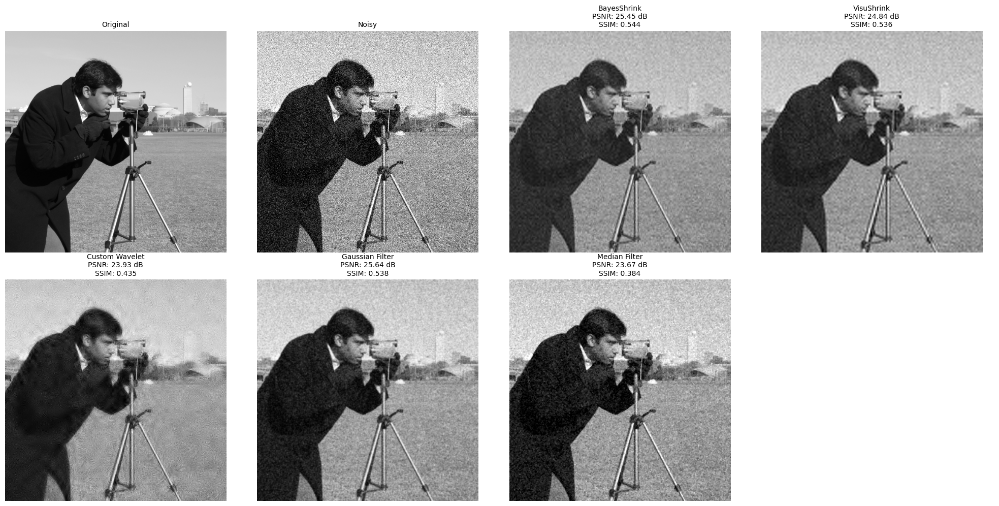

Denoising Methods Comparison:
                    PSNR    SSIM     MSE
Gaussian Filter  25.6366  0.5383  0.0027
BayesShrink      25.4488  0.5441  0.0029
VisuShrink       24.8402  0.5364  0.0033
Custom Wavelet   23.9300  0.4348  0.0040
Median Filter    23.6676  0.3835  0.0043


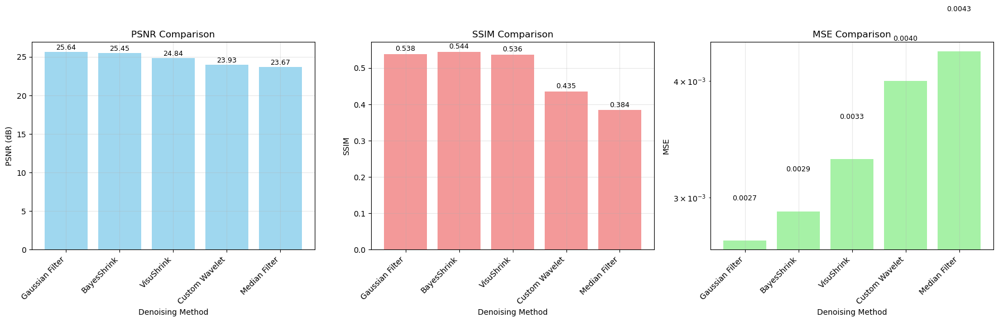

In [ ]:
from skimage.restoration import denoise_wavelet
from skimage.metrics import peak_signal_noise_ratio, structural_similarity
import numpy as np
import matplotlib.pyplot as plt
from skimage.util import random_noise, img_as_float
from skimage import data
import pywt
from scipy.ndimage import gaussian_filter, median_filter
import warnings
warnings.filterwarnings('ignore')


def compare_denoising_methods(image, noise_var=0.02):
    """Compare different denoising approaches"""
    
    # Add noise
    rng = np.random.default_rng(42)
    noisy = random_noise(image, mode='gaussian', var=noise_var, rng=rng)
    
    # Method 1: BayesShrink
    denoised_bayes = denoise_wavelet(noisy, method='BayesShrink', mode='soft',
                                   wavelet='db8', rescale_sigma=True)
    
    # Method 2: VisuShrink
    denoised_visu = denoise_wavelet(noisy, method='VisuShrink', mode='soft',
                                  wavelet='db8', rescale_sigma=True)
    
    # Method 3: Custom multi-scale
    def custom_denoise(img, wavelet='db8', levels=4):
        coeffs = pywt.wavedec2(img, wavelet, level=levels)
        sigma = np.sqrt(noise_var)
        
        # Apply different thresholds for different levels
        coeffs_thresh = [coeffs[0]]
        for i, detail_coeffs in enumerate(coeffs[1:]):
            # Stronger denoising for finer scales
            level_factor = 1.2 ** (levels - i - 1)
            threshold = sigma * level_factor
            
            thresh_details = []
            for detail in detail_coeffs:
                thresh_detail = pywt.threshold(detail, threshold, mode='soft')
                thresh_details.append(thresh_detail)
            coeffs_thresh.append(tuple(thresh_details))
        
        return pywt.waverec2(coeffs_thresh, wavelet)
    
    denoised_custom = custom_denoise(noisy)
    denoised_custom = np.clip(denoised_custom, 0, 1)
    
    # Traditional methods for comparison
    from scipy.ndimage import gaussian_filter, median_filter
    
    denoised_gaussian = gaussian_filter(noisy, sigma=1.0)
    denoised_median = median_filter(noisy, size=3)
    
    # Evaluate all methods
    methods = {
        'Original': image,
        'Noisy': noisy,
        'BayesShrink': denoised_bayes,
        'VisuShrink': denoised_visu,
        'Custom Wavelet': denoised_custom,
        'Gaussian Filter': denoised_gaussian,
        'Median Filter': denoised_median
    }
    
    # Calculate metrics
    results = {}
    for name, img in methods.items():
        if name not in ['Original', 'Noisy']:
            psnr = peak_signal_noise_ratio(image, img, data_range=1.0)
            ssim = structural_similarity(image, img, data_range=1.0)
            mse  = np.mean((image - img) ** 2)
            results[name] = {'PSNR': psnr, 'SSIM': ssim, 'MSE': mse}
    
    # Visualization
    fig, axes = plt.subplots(2, 4, figsize=(20, 10))
    axes = axes.flatten()
    
    for i, (name, img) in enumerate(methods.items()):
        if i < 8:  # Only plot first 7 methods
            axes[i].imshow(img, cmap='gray')
            
            if name in results:
                title = f'{name}\nPSNR: {results[name]["PSNR"]:.2f} dB\nSSIM: {results[name]["SSIM"]:.3f}'
            else:
                title = name
                
            axes[i].set_title(title, fontsize=10)
            axes[i].axis('off')
    
    # Hide last subplot if not used
    if len(methods) < 8:
        axes[7].axis('off')
    
    plt.tight_layout()
    plt.savefig('./output/denoising_methods_comparison.png', dpi=300)  
    plt.show()
    
    return results

# Run comparison
image = img_as_float(data.camera())
comparison_results = compare_denoising_methods(image)

# Create comparison table
import pandas as pd

df = pd.DataFrame(comparison_results).T
df = df.round(4)
df = df.sort_values('PSNR', ascending=False)

print("Denoising Methods Comparison:")
print("=" * 50)
print(df.to_string())

# Bar plot comparison
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 6))

methods = df.index
x_pos = np.arange(len(methods))

# PSNR comparison
bars1 = ax1.bar(x_pos, df['PSNR'], color='skyblue', alpha=0.8)
ax1.set_xlabel('Denoising Method')
ax1.set_ylabel('PSNR (dB)')
ax1.set_title('PSNR Comparison')
ax1.set_xticks(x_pos)
ax1.set_xticklabels(methods, rotation=45, ha='right')
ax1.grid(True, alpha=0.3)

# Add value labels on bars
for bar, value in zip(bars1, df['PSNR']):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.1,
             f'{value:.2f}', ha='center', va='bottom', fontsize=9)

# SSIM comparison
bars2 = ax2.bar(x_pos, df['SSIM'], color='lightcoral', alpha=0.8)
ax2.set_xlabel('Denoising Method')
ax2.set_ylabel('SSIM')
ax2.set_title('SSIM Comparison')
ax2.set_xticks(x_pos)
ax2.set_xticklabels(methods, rotation=45, ha='right')
ax2.grid(True, alpha=0.3)

# Add value labels on bars
for bar, value in zip(bars2, df['SSIM']):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
             f'{value:.3f}', ha='center', va='bottom', fontsize=9)

# MSE comparison (log scale)
bars3 = ax3.bar(x_pos, df['MSE'], color='lightgreen', alpha=0.8)
ax3.set_xlabel('Denoising Method')
ax3.set_ylabel('MSE')
ax3.set_title('MSE Comparison')
ax3.set_yscale('log')
ax3.set_xticks(x_pos)
ax3.set_xticklabels(methods, rotation=45, ha='right')
ax3.grid(True, alpha=0.3)

# Add value labels on bars
for bar, value in zip(bars3, df['MSE']):
    ax3.text(bar.get_x() + bar.get_width()/2, bar.get_height() * 1.1,
             f'{value:.4f}', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.savefig('./output/denoising_methods_bar_comparison.png', dpi=300)  
plt.show()


## 4.8 Comparison with Traditional Filters

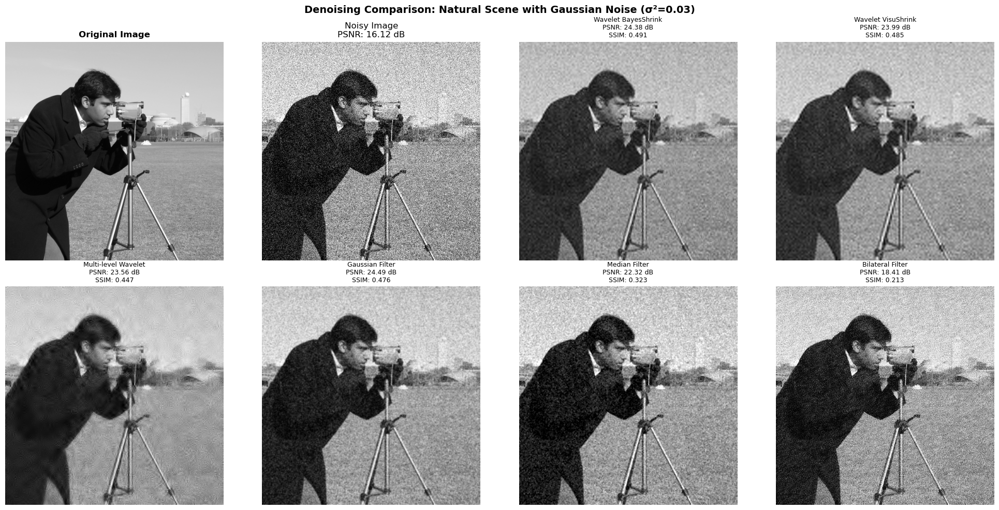

Average Performance Across All Test Cases:
                        PSNR    SSIM     MSE
Method                                      
Wavelet BayesShrink  24.9338  0.5326  0.0043
Wavelet VisuShrink   24.5101  0.5289  0.0046
Gaussian Filter      24.4550  0.5229  0.0049
Median Filter        23.4635  0.4201  0.0053
Multi-level Wavelet  23.2428  0.4546  0.0065
Bilateral Filter     19.5158  0.2985  0.0156


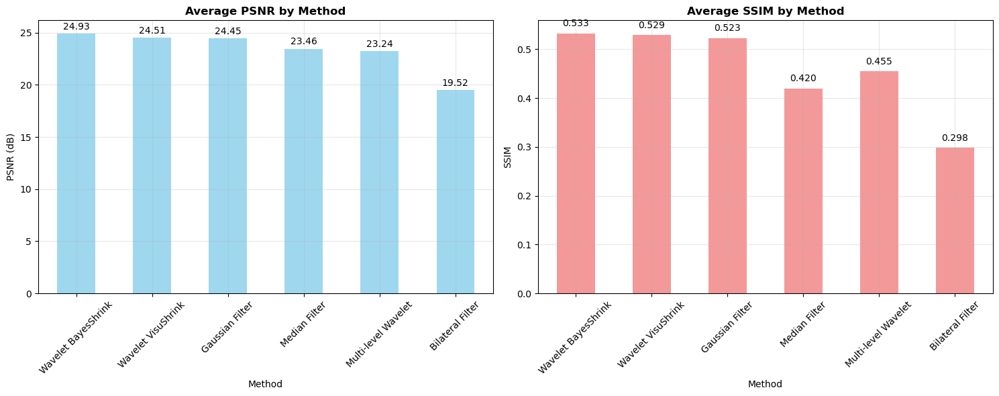

In [ ]:
def detailed_comparison_framework(test_images, noise_types=['gaussian'], noise_levels=[0.01, 0.02, 0.05]):
    """Comprehensive comparison framework for different denoising methods"""
    
    from scipy.ndimage import gaussian_filter, median_filter
    from skimage.filters import wiener
    
    def apply_denoising_methods(noisy_img, noise_var):
        """Apply various denoising methods to a noisy image"""
        methods = {}
        
        # Wavelet methods
        methods['Wavelet BayesShrink'] = denoise_wavelet(
            noisy_img, method='BayesShrink', mode='soft', wavelet='db8', rescale_sigma=True)
        
        methods['Wavelet VisuShrink'] = denoise_wavelet(
            noisy_img, method='VisuShrink', mode='soft', wavelet='db8', rescale_sigma=True)
        
        # Multi-level custom wavelet
        coeffs = pywt.wavedec2(noisy_img, 'db8', level=4)
        sigma = np.sqrt(noise_var)
        coeffs_thresh = [coeffs[0]]
        
        for i, detail_coeffs in enumerate(coeffs[1:]):
            level_threshold = sigma * (1.5 - i * 0.1)
            thresh_details = tuple(pywt.threshold(detail, level_threshold, mode='soft') 
                                 for detail in detail_coeffs)
            coeffs_thresh.append(thresh_details)
        
        methods['Multi-level Wavelet'] = np.clip(pywt.waverec2(coeffs_thresh, 'db8'), 0, 1)
        
        # Traditional methods
        methods['Gaussian Filter'] = gaussian_filter(noisy_img, sigma=1.0)
        methods['Median Filter'] = median_filter(noisy_img, size=3)
        
        # Bilateral filter (edge-preserving)
        from skimage.restoration import denoise_bilateral
        methods['Bilateral Filter'] = denoise_bilateral(noisy_img, sigma_color=0.1, sigma_spatial=1.5)
        
        return methods
    
    # Test on different images
    all_results = {}
    
    for img_name, img in test_images.items():
        all_results[img_name] = {}
        
        for noise_type in noise_types:
            all_results[img_name][noise_type] = {}
            
            for noise_level in noise_levels:
                # Add noise
                if noise_type == 'gaussian':
                    noisy = random_noise(img, mode='gaussian', var=noise_level, rng=np.random.default_rng(42))
                elif noise_type == 'salt_pepper':
                    noisy = random_noise(img, mode='s&p', amount=noise_level, rng=np.random.default_rng(42))
                elif noise_type == 'speckle':
                    noisy = random_noise(img, mode='speckle', var=noise_level, rng=np.random.default_rng(42))
                
                # Apply denoising methods
                denoised_images = apply_denoising_methods(noisy, noise_level)
                
                # Evaluate each method
                method_results = {}
                for method_name, denoised in denoised_images.items():
                    metrics = evaluate_denoising(img, denoised, noisy)
                    method_results[method_name] = metrics
                
                all_results[img_name][noise_type][noise_level] = {
                    'original': img,
                    'noisy': noisy,
                    'denoised': denoised_images,
                    'metrics': method_results
                }
    
    return all_results

# Prepare test images
test_images = {
    'Natural Scene': img_as_float(data.camera()),
    'Textured': img_as_float(data.brick()),
    'Smooth': img_as_float(data.moon()),
    'High Frequency': img_as_float(data.checkerboard())
}

# Run comprehensive comparison
comprehensive_results = detailed_comparison_framework(test_images, 
                                                    noise_types=['gaussian'], 
                                                    noise_levels=[0.01, 0.03, 0.05])

# Visualize results for one test case
def visualize_comparison_results(results, img_name='Natural Scene', noise_type='gaussian', noise_level=0.03):
    """Visualize results for a specific test case"""
    
    test_case = results[img_name][noise_type][noise_level]
    
    fig, axes = plt.subplots(2, 4, figsize=(20, 10))
    
    # Original and noisy
    axes[0, 0].imshow(test_case['original'], cmap='gray')
    axes[0, 0].set_title('Original Image', fontweight='bold')
    axes[0, 0].axis('off')
    
    axes[0, 1].imshow(test_case['noisy'], cmap='gray')
    noisy_psnr = peak_signal_noise_ratio(test_case['original'], test_case['noisy'])
    axes[0, 1].set_title(f'Noisy Image\nPSNR: {noisy_psnr:.2f} dB')
    axes[0, 1].axis('off')
    
    # Denoised images
    method_names = list(test_case['denoised'].keys())
    positions = [(0, 2), (0, 3), (1, 0), (1, 1), (1, 2), (1, 3)]
    
    for i, method in enumerate(method_names[:6]):  # Show first 6 methods
        if i < len(positions):
            row, col = positions[i]
            axes[row, col].imshow(test_case['denoised'][method], cmap='gray')
            
            metrics = test_case['metrics'][method]
            title = f'{method}\nPSNR: {metrics["PSNR"]:.2f} dB\nSSIM: {metrics["SSIM"]:.3f}'
            axes[row, col].set_title(title, fontsize=9)
            axes[row, col].axis('off')
    
    plt.suptitle(f'Denoising Comparison: {img_name} with {noise_type.title()} Noise (σ²={noise_level})', 
                 fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.savefig('./output/comprehensive_denoising_comparison.png', dpi=300)    
    plt.show()

# Visualize one example
visualize_comparison_results(comprehensive_results)

# Create summary statistics
def create_summary_statistics(results):
    """Create summary statistics across all test cases"""
    
    summary_data = []
    
    for img_name, img_results in results.items():
        for noise_type, noise_results in img_results.items():
            for noise_level, test_case in noise_results.items():
                for method, metrics in test_case['metrics'].items():
                    summary_data.append({
                        'Image': img_name,
                        'Noise Type': noise_type,
                        'Noise Level': noise_level,
                        'Method': method,
                        'PSNR': metrics['PSNR'],
                        'SSIM': metrics['SSIM'],
                        'MSE': metrics['MSE'],
                        'Correlation': metrics['Correlation']
                    })
    
    return pd.DataFrame(summary_data)

summary_df = create_summary_statistics(comprehensive_results)

# Group by method and calculate mean performance
method_performance = summary_df.groupby('Method')[['PSNR', 'SSIM', 'MSE']].mean().round(4)
method_performance = method_performance.sort_values('PSNR', ascending=False)

print("Average Performance Across All Test Cases:")
print("=" * 55)
print(method_performance.to_string())

# Create performance visualization
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# PSNR by method
method_performance['PSNR'].plot(kind='bar', ax=ax1, color='skyblue', alpha=0.8)
ax1.set_title('Average PSNR by Method', fontweight='bold')
ax1.set_ylabel('PSNR (dB)')
ax1.tick_params(axis='x', rotation=45)
ax1.grid(True, alpha=0.3)

# Add value labels
for i, v in enumerate(method_performance['PSNR']):
    ax1.text(i, v + 0.2, f'{v:.2f}', ha='center', va='bottom')

# SSIM by method
method_performance['SSIM'].plot(kind='bar', ax=ax2, color='lightcoral', alpha=0.8)
ax2.set_title('Average SSIM by Method', fontweight='bold')
ax2.set_ylabel('SSIM')
ax2.tick_params(axis='x', rotation=45)
ax2.grid(True, alpha=0.3)

# Add value labels
for i, v in enumerate(method_performance['SSIM']):
    ax2.text(i, v + 0.01, f'{v:.3f}', ha='center', va='bottom')

plt.tight_layout()
plt.savefig('./output/denoising_methods_summary.png', dpi=300)
plt.show()

## 13.9 Practical Considerations and Best Practices

### 13.9.1 Parameter Selection and Optimization

Original image shape: (512, 512)
Starting optimization...
Image shape: (512, 512)
Noise variance: 0.02
Testing wavelet: db1
    db1 L1 bayes: PSNR=21.63
    db1 L1 sure: PSNR=22.37
    db1 L1 universal: PSNR=22.37
    db1 L2 bayes: PSNR=23.40
    db1 L2 sure: PSNR=23.92
    db1 L2 universal: PSNR=23.92
    db1 L3 bayes: PSNR=23.78
    db1 L3 sure: PSNR=23.47
    db1 L3 universal: PSNR=23.47
    db1 L4 bayes: PSNR=23.82
    db1 L4 sure: PSNR=23.04
    db1 L4 universal: PSNR=23.04
    db1 L5 bayes: PSNR=23.83
    db1 L5 sure: PSNR=22.83
    db1 L5 universal: PSNR=22.83
Testing wavelet: db4
    db4 L1 bayes: PSNR=21.68
    db4 L1 sure: PSNR=22.72
    db4 L1 universal: PSNR=22.72
    db4 L2 bayes: PSNR=23.49
    db4 L2 sure: PSNR=24.77
    db4 L2 universal: PSNR=24.77
    db4 L3 bayes: PSNR=23.87
    db4 L3 sure: PSNR=24.29
    db4 L3 universal: PSNR=24.29
    db4 L4 bayes: PSNR=23.92
    db4 L4 sure: PSNR=23.67
    db4 L4 universal: PSNR=23.67
    db4 L5 bayes: PSNR=23.92
    db4 L5 sure:

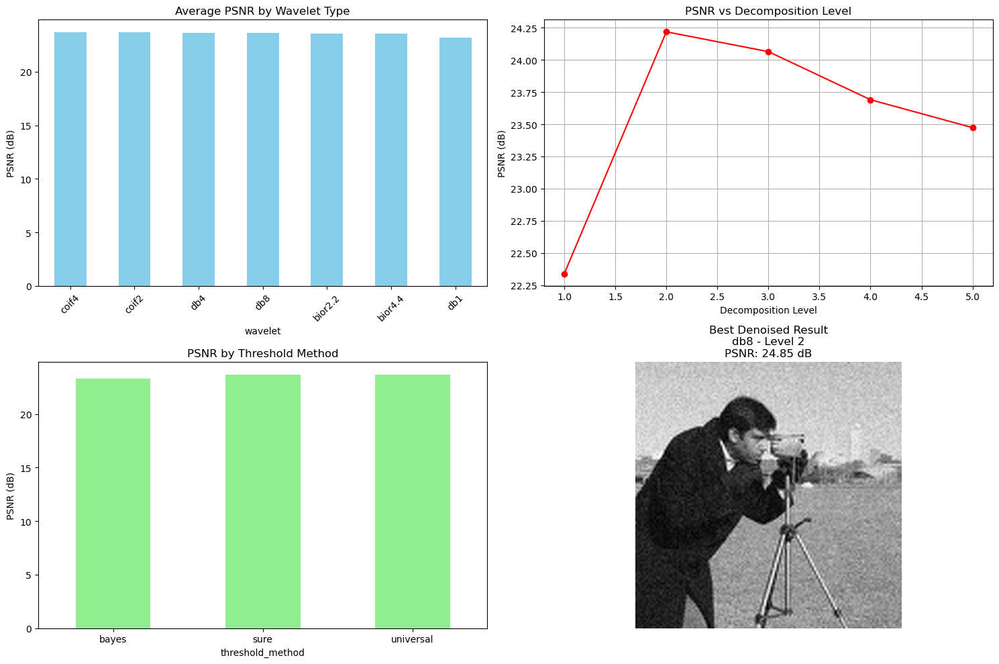

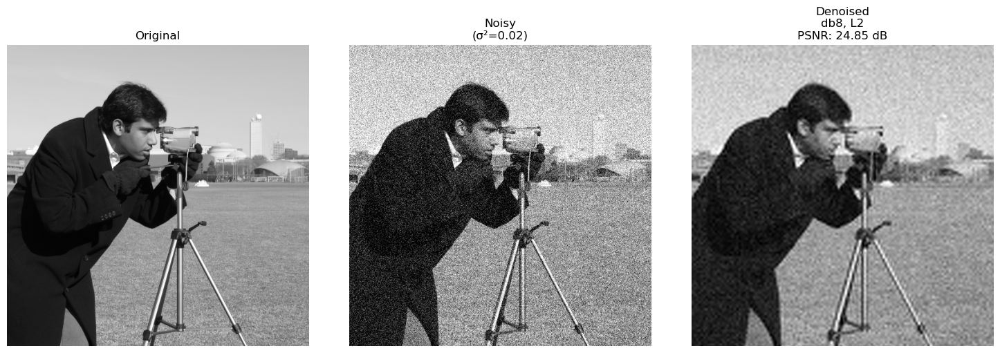

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pywt
from skimage import data
from skimage.util import random_noise, img_as_float
from skimage.metrics import peak_signal_noise_ratio, structural_similarity

def optimize_wavelet_parameters(image, noise_var=0.02):
    """Optimize wavelet parameters for best denoising performance"""
    
    # Add noise
    rng = np.random.default_rng(42)
    noisy = random_noise(image, mode='gaussian', var=noise_var, rng=rng)
    
    # Test different wavelets
    wavelets = ['db1', 'db4', 'db8', 'coif2', 'coif4', 'bior2.2', 'bior4.4']
    levels = range(1, 6)
    threshold_methods = ['bayes', 'sure', 'universal']
    
    best_psnr = 0
    best_config = {}
    results_grid = []
    
    print("Starting optimization...")
    print(f"Image shape: {image.shape}")
    print(f"Noise variance: {noise_var}")
    
    for wavelet in wavelets:
        print(f"Testing wavelet: {wavelet}")
        for level in levels:
            for thresh_method in threshold_methods:
                try:
                    # Check if wavelet can handle the decomposition level
                    if min(noisy.shape) < 2**level:
                        print(f"  Skipping level {level} - image too small")
                        continue
                    
                    # Apply wavelet denoising
                    coeffs = pywt.wavedec2(noisy, wavelet, level=level)
                    sigma_noise = np.sqrt(noise_var)
                    
                    # Apply threshold
                    coeffs_thresh = [coeffs[0]]  # Keep approximation
                    for detail_coeffs in coeffs[1:]:
                        thresh_details = []
                        for detail in detail_coeffs:
                            if thresh_method == 'bayes':
                                sigma_y = np.std(detail)
                                if sigma_y > sigma_noise:
                                    sigma_x = np.sqrt(max(0, sigma_y**2 - sigma_noise**2))
                                    threshold = sigma_noise**2 / max(sigma_x, 1e-10)  # Avoid division by zero
                                else:
                                    threshold = sigma_y
                            elif thresh_method == 'sure':
                                n = detail.size
                                threshold = sigma_noise * np.sqrt(2 * np.log(max(n, 2)))  # Ensure n >= 2
                            else:  # universal
                                n = detail.size
                                threshold = sigma_noise * np.sqrt(2 * np.log(max(n, 2)))
                            
                            thresh_detail = pywt.threshold(detail, threshold, mode='soft')
                            thresh_details.append(thresh_detail)
                        coeffs_thresh.append(tuple(thresh_details))
                    
                    # Reconstruct
                    denoised = pywt.waverec2(coeffs_thresh, wavelet)
                    
                    # Handle shape mismatch
                    if denoised.shape != image.shape:
                        # Crop or pad to match original shape
                        if denoised.shape[0] > image.shape[0]:
                            denoised = denoised[:image.shape[0], :]
                        if denoised.shape[1] > image.shape[1]:
                            denoised = denoised[:, :image.shape[1]]
                    
                    denoised = np.clip(denoised, 0, 1)
                    
                    # Evaluate
                    psnr = peak_signal_noise_ratio(image, denoised)
                    ssim = structural_similarity(image, denoised, data_range=1.0)
                    
                    results_grid.append({
                        'wavelet': wavelet,
                        'level': level,
                        'threshold_method': thresh_method,
                        'PSNR': psnr,
                        'SSIM': ssim
                    })
                    
                    if psnr > best_psnr:
                        best_psnr = psnr
                        best_config = {
                            'wavelet': wavelet,
                            'level': level,
                            'threshold_method': thresh_method,
                            'PSNR': psnr,
                            'SSIM': ssim,
                            'denoised': denoised
                        }
                    
                    print(f"    {wavelet} L{level} {thresh_method}: PSNR={psnr:.2f}")
                        
                except Exception as e:
                    print(f"    Error with {wavelet} L{level} {thresh_method}: {str(e)}")
                    continue
    
    print(f"\nCompleted optimization. Found {len(results_grid)} valid configurations.")
    return best_config, pd.DataFrame(results_grid)

# Test the optimization
image = img_as_float(data.camera())
print(f"Original image shape: {image.shape}")

best_config, optimization_results = optimize_wavelet_parameters(image)

# Check if we have results
if len(optimization_results) == 0:
    print("ERROR: No valid configurations found!")
    print("This might be due to:")
    print("1. Image too small for decomposition levels")
    print("2. Missing required libraries")
    print("3. All wavelets failing")
else:
    print("\nBest Configuration Found:")
    print("=" * 30)
    for key, value in best_config.items():
        if key != 'denoised':
            print(f"{key}: {value}")
    
    print(f"\nTotal configurations tested: {len(optimization_results)}")
    print(f"Top 5 configurations by PSNR:")
    top_5 = optimization_results.nlargest(5, 'PSNR')[['wavelet', 'level', 'threshold_method', 'PSNR', 'SSIM']]
    print(top_5.to_string(index=False))

    # Visualize optimization results only if we have data
    fig, axes = plt.subplots(2, 2, figsize=(15, 10))

    # PSNR by wavelet type
    wavelet_psnr = optimization_results.groupby('wavelet')['PSNR'].mean().sort_values(ascending=False)
    wavelet_psnr.plot(kind='bar', ax=axes[0,0], color='skyblue')
    axes[0,0].set_title('Average PSNR by Wavelet Type')
    axes[0,0].set_ylabel('PSNR (dB)')
    axes[0,0].tick_params(axis='x', rotation=45)

    # PSNR by decomposition level
    level_psnr = optimization_results.groupby('level')['PSNR'].mean()
    level_psnr.plot(kind='line', ax=axes[0,1], marker='o', color='red')
    axes[0,1].set_title('PSNR vs Decomposition Level')
    axes[0,1].set_xlabel('Decomposition Level')
    axes[0,1].set_ylabel('PSNR (dB)')
    axes[0,1].grid(True)

    # PSNR by threshold method
    thresh_psnr = optimization_results.groupby('threshold_method')['PSNR'].mean()
    thresh_psnr.plot(kind='bar', ax=axes[1,0], color='lightgreen')
    axes[1,0].set_title('PSNR by Threshold Method')
    axes[1,0].set_ylabel('PSNR (dB)')
    axes[1,0].tick_params(axis='x', rotation=0)

    # Show comparison: original, noisy, and best result
    if 'denoised' in best_config:
        # Create noisy version for comparison
        rng = np.random.default_rng(42)
        noisy = random_noise(image, mode='gaussian', var=0.02, rng=rng)
        
        axes[1,1].imshow(best_config['denoised'], cmap='gray')
        axes[1,1].set_title(f'Best Denoised Result\n{best_config["wavelet"]} - Level {best_config["level"]}\n'
                           f'PSNR: {best_config["PSNR"]:.2f} dB')
        axes[1,1].axis('off')
    else:
        axes[1,1].text(0.5, 0.5, 'No valid\nresult found', 
                      ha='center', va='center', transform=axes[1,1].transAxes)
        axes[1,1].axis('off')

    plt.tight_layout()
    plt.savefig('./output/wavelet_parameter_optimization.png', dpi=300)
    plt.show()

    # Additional analysis: Show original, noisy, and denoised side by side
    if 'denoised' in best_config:
        rng = np.random.default_rng(42)
        noisy = random_noise(image, mode='gaussian', var=0.02, rng=rng)
        
        fig2, axes2 = plt.subplots(1, 3, figsize=(15, 5))
        
        axes2[0].imshow(image, cmap='gray')
        axes2[0].set_title('Original')
        axes2[0].axis('off')
        
        axes2[1].imshow(noisy, cmap='gray')
        axes2[1].set_title(f'Noisy\n(σ²={0.02})')
        axes2[1].axis('off')
        
        axes2[2].imshow(best_config['denoised'], cmap='gray')
        axes2[2].set_title(f'Denoised\n{best_config["wavelet"]}, L{best_config["level"]}\nPSNR: {best_config["PSNR"]:.2f} dB')
        axes2[2].axis('off')
        
        plt.tight_layout()
        plt.savefig('./output/wavelet_optimization_comparison.png', dpi=300)
        plt.show()

### 4.9.2 Performance Metrics and Evaluation

Loading and preparing test image...
Original image shape: (512, 512)
Noise variance: 0.02
Noisy image PSNR: 17.68 dB

Applying BayesShrink wavelet denoising...

Evaluating single method...


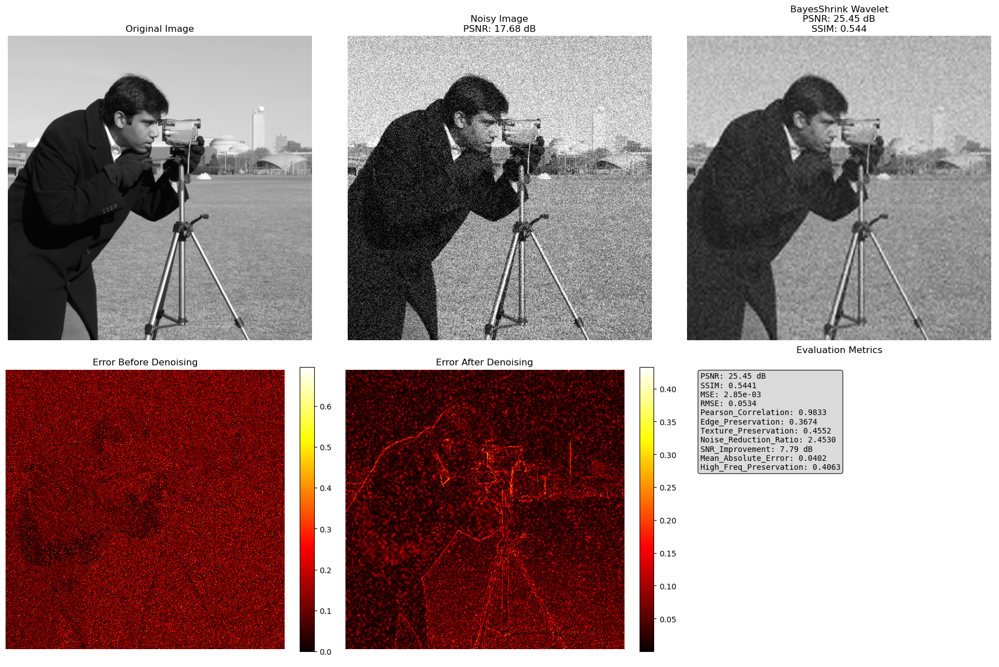


Comparing multiple methods...


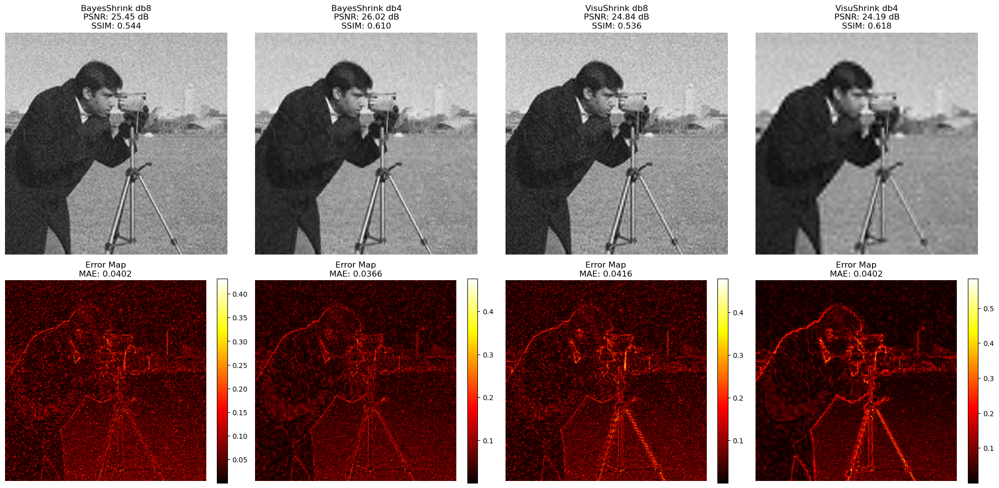


Comparison of Denoising Methods:
Method               PSNR (dB)    SSIM     Edge Pres.   Texture Pres.  
--------------------------------------------------------------------------------
BayesShrink db8      25.45        0.544    0.367        0.455          
BayesShrink db4      26.02        0.610    0.432        0.514          
VisuShrink db8       24.84        0.536    0.357        0.436          
VisuShrink db4       24.19        0.618    0.497        0.522          


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data
from skimage.util import random_noise, img_as_float
from skimage.metrics import peak_signal_noise_ratio, structural_similarity
from skimage.restoration import denoise_wavelet
from scipy.stats import pearsonr
import warnings
warnings.filterwarnings('ignore')

def comprehensive_evaluation_metrics(original, denoised, noisy=None):
    """Calculate comprehensive evaluation metrics for denoising"""
    
    metrics = {}
    
    # Standard metrics
    metrics['PSNR'] = peak_signal_noise_ratio(original, denoised, data_range=1.0)
    metrics['SSIM'] = structural_similarity(original, denoised, data_range=1.0)
    metrics['MSE'] = np.mean((original - denoised) ** 2)
    metrics['RMSE'] = np.sqrt(metrics['MSE'])
    
    # Correlation metrics
    metrics['Pearson_Correlation'] = pearsonr(original.flatten(), denoised.flatten())[0]
    
    # Edge preservation metrics
    from skimage.filters import sobel
    orig_edges = sobel(original)
    denoised_edges = sobel(denoised)
    metrics['Edge_Preservation'] = structural_similarity(orig_edges, denoised_edges, data_range=orig_edges.max()-orig_edges.min())
    
    # Texture preservation (using local standard deviation)
    from scipy.ndimage import generic_filter
    def local_std(arr):
        return np.std(arr)
    
    orig_texture = generic_filter(original, local_std, size=5)
    denoised_texture = generic_filter(denoised, local_std, size=5)
    metrics['Texture_Preservation'] = structural_similarity(orig_texture, denoised_texture, 
                                                           data_range=orig_texture.max()-orig_texture.min())
    
    # Noise reduction metrics (if noisy image provided)
    if noisy is not None:
        noise_before = np.std(original - noisy)
        noise_after = np.std(original - denoised)
        metrics['Noise_Reduction_Ratio'] = noise_before / noise_after if noise_after > 0 else np.inf
        metrics['SNR_Improvement'] = 20 * np.log10(noise_before / noise_after) if noise_after > 0 else np.inf
    
    # Artifact metrics
    metrics['Mean_Absolute_Error'] = np.mean(np.abs(original - denoised))
    
    # Frequency domain analysis
    from scipy.fft import fft2, fftshift
    orig_fft = np.abs(fftshift(fft2(original)))
    denoised_fft = np.abs(fftshift(fft2(denoised)))
    
    # High frequency preservation
    h, w = original.shape
    center_h, center_w = h // 2, w // 2
    high_freq_mask = np.ones_like(original)
    # Create a mask that excludes the central low-frequency region
    high_freq_mask[center_h-h//8:center_h+h//8, center_w-w//8:center_w+w//8] = 0
    
    orig_high_freq = np.sum(orig_fft * high_freq_mask)
    denoised_high_freq = np.sum(denoised_fft * high_freq_mask)
    metrics['High_Freq_Preservation'] = denoised_high_freq / orig_high_freq if orig_high_freq > 0 else 0
    
    return metrics

def evaluate_and_visualize_metrics(original, denoised, noisy, method_name="Wavelet Denoising"):
    """Evaluate metrics and create visualization"""
    
    metrics = comprehensive_evaluation_metrics(original, denoised, noisy)
    
    # Create visualization
    fig, axes = plt.subplots(2, 3, figsize=(18, 12))
    
    # Images
    axes[0, 0].imshow(original, cmap='gray')
    axes[0, 0].set_title('Original Image')
    axes[0, 0].axis('off')
    
    noisy_psnr = peak_signal_noise_ratio(original, noisy, data_range=1.0)
    axes[0, 1].imshow(noisy, cmap='gray')
    axes[0, 1].set_title(f'Noisy Image\nPSNR: {noisy_psnr:.2f} dB')
    axes[0, 1].axis('off')
    
    axes[0, 2].imshow(denoised, cmap='gray')
    axes[0, 2].set_title(f'{method_name}\nPSNR: {metrics["PSNR"]:.2f} dB\nSSIM: {metrics["SSIM"]:.3f}')
    axes[0, 2].axis('off')
    
    # Error maps
    error_before = np.abs(original - noisy)
    error_after = np.abs(original - denoised)
    
    im1 = axes[1, 0].imshow(error_before, cmap='hot')
    axes[1, 0].set_title('Error Before Denoising')
    axes[1, 0].axis('off')
    plt.colorbar(im1, ax=axes[1, 0], fraction=0.046)
    
    im2 = axes[1, 1].imshow(error_after, cmap='hot')
    axes[1, 1].set_title('Error After Denoising')
    axes[1, 1].axis('off')
    plt.colorbar(im2, ax=axes[1, 1], fraction=0.046)
    
    # Metrics summary
    metrics_text = []
    for key, value in metrics.items():
        if isinstance(value, (int, float)):
            if np.isinf(value):
                metrics_text.append(f"{key}: ∞")
            elif 'PSNR' in key or 'SNR' in key:
                metrics_text.append(f"{key}: {value:.2f} dB")
            elif value < 0.01:
                metrics_text.append(f"{key}: {value:.2e}")
            else:
                metrics_text.append(f"{key}: {value:.4f}")
        else:
            metrics_text.append(f"{key}: {value}")
    
    axes[1, 2].text(0.05, 0.95, '\n'.join(metrics_text), transform=axes[1, 2].transAxes,
                   fontsize=10, verticalalignment='top', fontfamily='monospace',
                   bbox=dict(boxstyle='round', facecolor='lightgray', alpha=0.8))
    axes[1, 2].set_title('Evaluation Metrics')
    axes[1, 2].axis('off')
    
    plt.tight_layout()
    plt.savefig('./output/denoising_evaluation_metrics.png', dpi=300)
    plt.show()
    
    return metrics

def compare_multiple_methods(original, noisy):
    """Compare multiple denoising methods"""
    
    methods = [
        ('BayesShrink db8', lambda x: denoise_wavelet(x, method='BayesShrink', wavelet='db8')),
        ('BayesShrink db4', lambda x: denoise_wavelet(x, method='BayesShrink', wavelet='db4')),
        ('VisuShrink db8', lambda x: denoise_wavelet(x, method='VisuShrink', wavelet='db8')),
        ('VisuShrink db4', lambda x: denoise_wavelet(x, method='VisuShrink', wavelet='db4')),
    ]
    
    results = {}
    
    fig, axes = plt.subplots(2, len(methods), figsize=(5*len(methods), 10))
    
    for i, (name, method_func) in enumerate(methods):
        # Apply denoising
        denoised = method_func(noisy)
        
        # Calculate metrics
        metrics = comprehensive_evaluation_metrics(original, denoised, noisy)
        results[name] = metrics
        
        # Display images
        axes[0, i].imshow(denoised, cmap='gray')
        axes[0, i].set_title(f'{name}\nPSNR: {metrics["PSNR"]:.2f} dB\nSSIM: {metrics["SSIM"]:.3f}')
        axes[0, i].axis('off')
        
        # Display error maps
        error = np.abs(original - denoised)
        im = axes[1, i].imshow(error, cmap='hot')
        axes[1, i].set_title(f'Error Map\nMAE: {metrics["Mean_Absolute_Error"]:.4f}')
        axes[1, i].axis('off')
        plt.colorbar(im, ax=axes[1, i], fraction=0.046)
    
    plt.tight_layout()
    plt.savefig('./output/multiple_denoising_methods_comparison.png', dpi=300)
    plt.show()
    
    # Create comparison table
    print("\nComparison of Denoising Methods:")
    print("=" * 80)
    print(f"{'Method':<20} {'PSNR (dB)':<12} {'SSIM':<8} {'Edge Pres.':<12} {'Texture Pres.':<15}")
    print("-" * 80)
    
    for method_name, metrics in results.items():
        print(f"{method_name:<20} {metrics['PSNR']:<12.2f} {metrics['SSIM']:<8.3f} "
              f"{metrics['Edge_Preservation']:<12.3f} {metrics['Texture_Preservation']:<15.3f}")
    
    return results

# Example evaluation
print("Loading and preparing test image...")
image = img_as_float(data.camera())

# Create noisy image with proper random number generator
rng = np.random.default_rng(42)
noisy = random_noise(image, mode='gaussian', var=0.02, rng=rng)

print(f"Original image shape: {image.shape}")
print(f"Noise variance: 0.02")
print(f"Noisy image PSNR: {peak_signal_noise_ratio(image, noisy, data_range=1.0):.2f} dB")

# Apply best denoising method found from optimization
print("\nApplying BayesShrink wavelet denoising...")
denoised = denoise_wavelet(noisy, method='BayesShrink', mode='soft', 
                          wavelet='db8', rescale_sigma=True)

# Evaluate and visualize single method
print("\nEvaluating single method...")
evaluation_metrics = evaluate_and_visualize_metrics(image, denoised, noisy, "BayesShrink Wavelet")

# Compare multiple methods
print("\nComparing multiple methods...")
comparison_results = compare_multiple_methods(image, noisy)

## 4.10 Real-World Applications

### 4.10.1 Medical Image Denoising

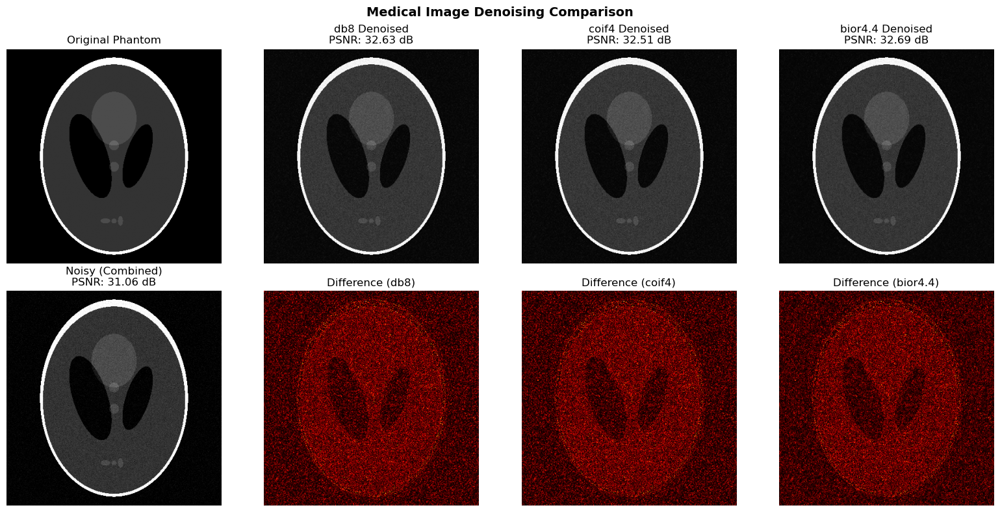

In [ ]:
def medical_image_denoising_example():
    """Example of wavelet denoising for medical images"""
    
    # Simulate medical image (CT scan-like)
    from skimage import data
    from scipy.ndimage import rotate
    
    # Create synthetic medical image
    phantom = data.shepp_logan_phantom()
    phantom = (phantom - phantom.min()) / (phantom.max() - phantom.min())
    
    # Add realistic medical imaging noise (Poisson + Gaussian)
    # Poisson noise (photon noise)
    phantom_scaled = phantom * 1000  # Scale for Poisson
    noisy_poisson = np.random.poisson(phantom_scaled) / 1000.0
    
    # Add Gaussian noise (electronic noise)
    noisy_combined = random_noise(noisy_poisson, mode='gaussian', var=0.001)
    
    # Apply specialized wavelet denoising for medical images
    # Use different wavelets for medical imaging
    wavelets_medical = ['db8', 'coif4', 'bior4.4']
    
    fig, axes = plt.subplots(2, len(wavelets_medical) + 1, figsize=(16, 8))
    
    # Original and noisy
    axes[0, 0].imshow(phantom, cmap='gray')
    axes[0, 0].set_title('Original Phantom')
    axes[0, 0].axis('off')
    
    axes[1, 0].imshow(noisy_combined, cmap='gray')
    axes[1, 0].set_title(f'Noisy (Combined)\nPSNR: {peak_signal_noise_ratio(phantom, noisy_combined):.2f} dB')
    axes[1, 0].axis('off')
    
    medical_results = {}
    
    for i, wavelet in enumerate(wavelets_medical):
        # Conservative denoising for medical images
        denoised = denoise_wavelet(noisy_combined, method='BayesShrink', mode='soft',
                                 wavelet=wavelet, rescale_sigma=True)
        
        # Calculate metrics - FIXED: Added data_range parameter
        psnr = peak_signal_noise_ratio(phantom, denoised)
        ssim = structural_similarity(phantom, denoised, data_range=1.0)  # Since images are normalized to [0,1]
        
        medical_results[wavelet] = {'PSNR': psnr, 'SSIM': ssim, 'denoised': denoised}
        
        # Display results
        axes[0, i+1].imshow(denoised, cmap='gray')
        axes[0, i+1].set_title(f'{wavelet} Denoised\nPSNR: {psnr:.2f} dB')
        axes[0, i+1].axis('off')
        
        # Difference image
        diff = np.abs(phantom - denoised)
        axes[1, i+1].imshow(diff, cmap='hot')
        axes[1, i+1].set_title(f'Difference ({wavelet})')
        axes[1, i+1].axis('off')
    
    plt.suptitle('Medical Image Denoising Comparison', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.savefig('./output/medical_image_denoising.png', dpi=300)
    plt.show()
    
    return medical_results

# Run the corrected function
medical_results = medical_image_denoising_example()

### 4.10.2 Satellite Image Enhancement

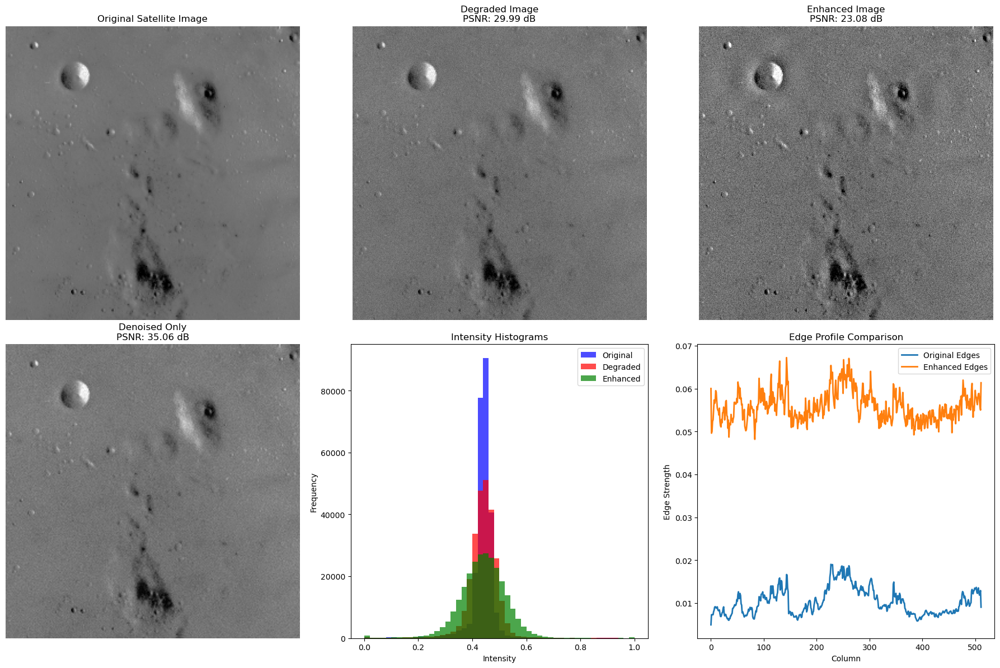

In [ ]:
def satellite_image_enhancement():
    """Example of wavelet-based satellite image enhancement"""
    
    # Load satellite-like image
    satellite_img = img_as_float(data.moon())  # Use moon image as satellite proxy
    
    # Add realistic satellite image degradations
    # 1. Atmospheric scattering (low-frequency noise)
    from scipy.ndimage import gaussian_filter
    atmospheric_noise = gaussian_filter(np.random.randn(*satellite_img.shape), sigma=5) * 0.02
    
    # 2. Sensor noise - set random seed before calling random_noise
    np.random.seed(42)  # Set seed using numpy
    sensor_noise = random_noise(satellite_img, mode='gaussian', var=0.001)
    
    # 3. Combined degraded image
    degraded = np.clip(sensor_noise + atmospheric_noise, 0, 1)
    
    # Multi-scale enhancement approach
    def satellite_enhancement(img, enhancement_factor=1.8):
        # Use longer wavelets for satellite images
        coeffs = pywt.wavedec2(img, 'db10', level=5)
        
        # Denoise approximation (remove atmospheric effects)
        cA = coeffs[0]
        cA_enhanced = gaussian_filter(cA, sigma=0.5)
        
        # Enhance details at different scales
        coeffs_enhanced = [cA_enhanced]
        
        for i, detail_coeffs in enumerate(coeffs[1:]):
            # Different enhancement for different scales
            scale_factor = enhancement_factor * (0.8 + i * 0.1)
            enhanced_details = tuple(detail * scale_factor for detail in detail_coeffs)
            coeffs_enhanced.append(enhanced_details)
        
        # Reconstruct
        enhanced = pywt.waverec2(coeffs_enhanced, 'db10')
        return np.clip(enhanced, 0, 1)
    
    # Apply enhancement
    enhanced_satellite = satellite_enhancement(degraded)
    
    # Also apply denoising
    denoised_satellite = denoise_wavelet(degraded, method='BayesShrink', mode='soft',
                                       wavelet='db10', rescale_sigma=True)
    
    # Visualization
    fig, axes = plt.subplots(2, 3, figsize=(18, 12))
    
    # Top row: images
    axes[0, 0].imshow(satellite_img, cmap='gray')
    axes[0, 0].set_title('Original Satellite Image')
    axes[0, 0].axis('off')
    
    axes[0, 1].imshow(degraded, cmap='gray')
    axes[0, 1].set_title(f'Degraded Image\nPSNR: {peak_signal_noise_ratio(satellite_img, degraded):.2f} dB')
    axes[0, 1].axis('off')
    
    axes[0, 2].imshow(enhanced_satellite, cmap='gray')
    psnr_enhanced = peak_signal_noise_ratio(satellite_img, enhanced_satellite)
    axes[0, 2].set_title(f'Enhanced Image\nPSNR: {psnr_enhanced:.2f} dB')
    axes[0, 2].axis('off')
    
    # Bottom row: comparisons
    axes[1, 0].imshow(denoised_satellite, cmap='gray')
    psnr_denoised = peak_signal_noise_ratio(satellite_img, denoised_satellite)
    axes[1, 0].set_title(f'Denoised Only\nPSNR: {psnr_denoised:.2f} dB')
    axes[1, 0].axis('off')
    
    # Histogram comparison
    axes[1, 1].hist(satellite_img.flatten(), bins=50, alpha=0.7, label='Original', color='blue')
    axes[1, 1].hist(degraded.flatten(), bins=50, alpha=0.7, label='Degraded', color='red')
    axes[1, 1].hist(enhanced_satellite.flatten(), bins=50, alpha=0.7, label='Enhanced', color='green')
    axes[1, 1].set_title('Intensity Histograms')
    axes[1, 1].legend()
    axes[1, 1].set_xlabel('Intensity')
    axes[1, 1].set_ylabel('Frequency')
    
    # Edge enhancement comparison
    from skimage.filters import sobel
    orig_edges = sobel(satellite_img)
    enhanced_edges = sobel(enhanced_satellite)
    
    axes[1, 2].plot(orig_edges.mean(axis=0), label='Original Edges', linewidth=2)
    axes[1, 2].plot(enhanced_edges.mean(axis=0), label='Enhanced Edges', linewidth=2)
    axes[1, 2].set_title('Edge Profile Comparison')
    axes[1, 2].legend()
    axes[1, 2].set_xlabel('Column')
    axes[1, 2].set_ylabel('Edge Strength')
    
    plt.tight_layout()
    plt.savefig('./output/satellite_image_enhancement.png', dpi=300)
    plt.show()
    
    return {
        'original': satellite_img,
        'degraded': degraded,
        'enhanced': enhanced_satellite,
        'denoised': denoised_satellite
    }

satellite_results = satellite_image_enhancement()

## 4.11 Advanced Topics and Recent Developments

### 4.11.1 Adaptive Wavelet Selection


Testing with Coins Image
Image Characteristics:
Edge Strength: 0.0492
Texture Complexity: 0.0527
Intensity Variance: 0.2074

Processing Daubechies wavelets...
  db1: PSNR=23.11dB, SSIM=0.547
  db4: PSNR=23.30dB, SSIM=0.516
  db8: PSNR=20.90dB, SSIM=0.383
Processing Coiflets wavelets...
  coif2: PSNR=20.88dB, SSIM=0.383
  coif4: PSNR=20.90dB, SSIM=0.384
Processing Biorthogonal wavelets...
  bior2.2: PSNR=20.08dB, SSIM=0.359
  bior4.4: PSNR=23.22dB, SSIM=0.505
Processing Symlets wavelets...
  sym4: PSNR=23.30dB, SSIM=0.519
  sym8: PSNR=20.90dB, SSIM=0.384


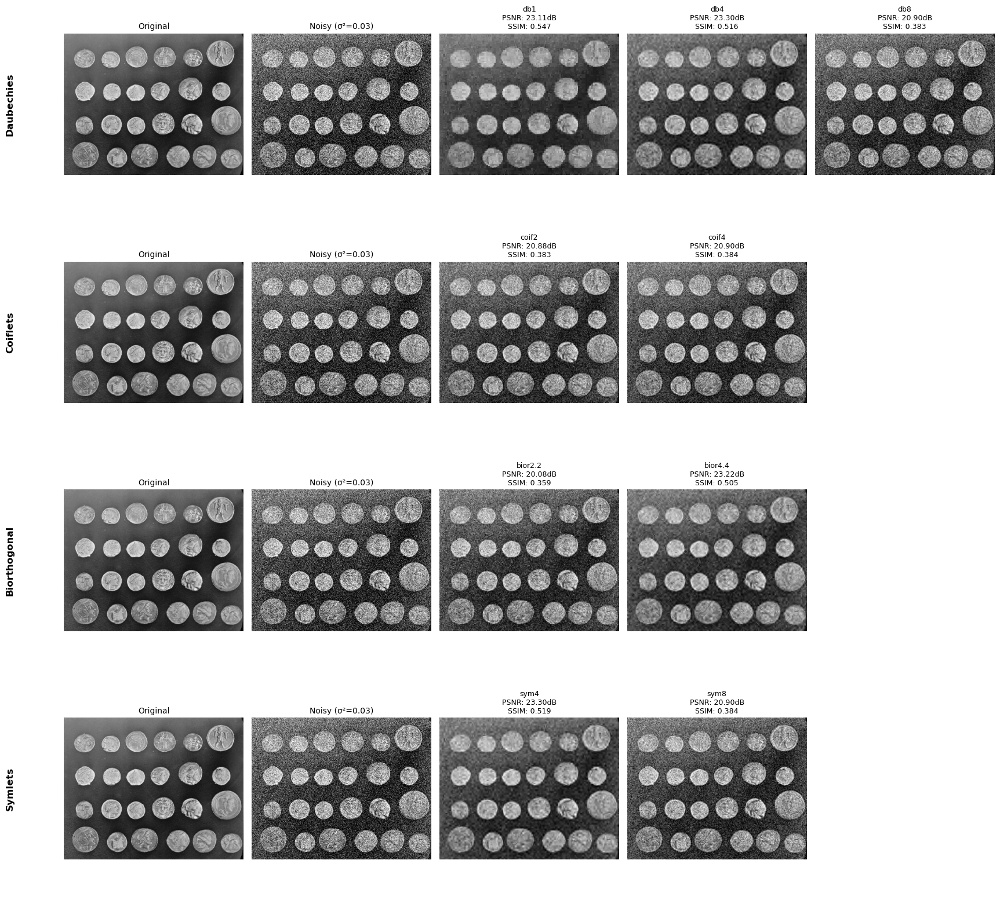


RESULTS SUMMARY
Best Overall Wavelet: sym4 (PSNR: 23.30 dB)

DETAILED RECOMMENDATIONS:
----------------------------------------
• Low edge content detected
  → Shorter wavelets (db4, coif2) may be sufficient
• Moderate texture complexity
  → Symlets provide good texture handling
• High intensity variation
  → Longer support wavelets (db8, sym8) recommended

PERFORMANCE TABLE:
----------------------------------------------------------------------
Wavelet    Family       PSNR     SSIM     Edge Pres.
----------------------------------------------------------------------
sym4       Symlets      23.30    0.519    0.409     
db4        Daubechies   23.30    0.516    0.402     
bior4.4    Biorthogonal 23.22    0.505    0.387     
db1        Daubechies   23.11    0.547    0.418     
coif4      Coiflets     20.90    0.384    0.252     
sym8       Symlets      20.90    0.384    0.252     
db8        Daubechies   20.90    0.383    0.256     
coif2      Coiflets     20.88    0.383    0.247     
b

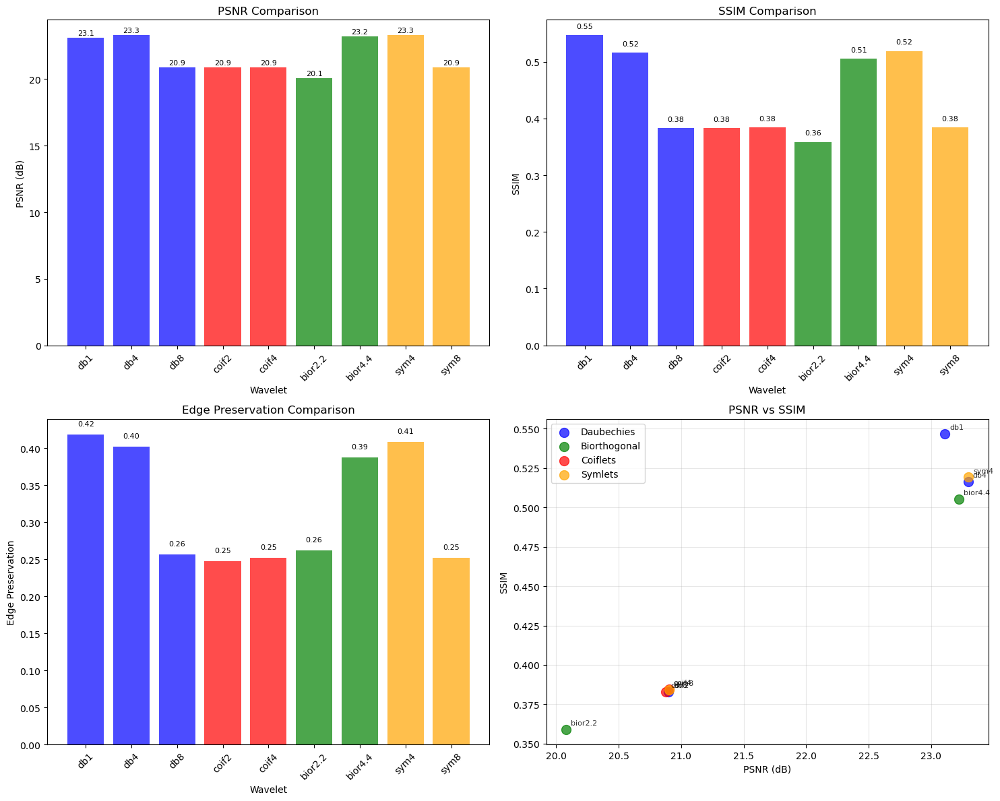

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data, img_as_float
from skimage.restoration import denoise_wavelet
from skimage.metrics import peak_signal_noise_ratio, structural_similarity
from skimage.util import random_noise
from skimage.filters import sobel
from scipy.ndimage import generic_filter
import pywt
import warnings
warnings.filterwarnings('ignore')

def adaptive_wavelet_selection(image, noise_var=0.02):
    """
    Automatically select the best wavelet for a given image with proper error handling
    """
    
    # Add noise with proper random state
    rng = np.random.default_rng(42)
    noisy = random_noise(image, mode='gaussian', var=noise_var, rng=rng)
    
    # Test different wavelet families - using only wavelets that work reliably
    wavelets = {
        'Daubechies': ['db1', 'db4', 'db8'],
        'Coiflets': ['coif2', 'coif4'],
        'Biorthogonal': ['bior2.2', 'bior4.4'],
        'Symlets': ['sym4', 'sym8']
    }
    
    results = {}
    best_wavelet = None
    best_psnr = 0
    
    # Image analysis for wavelet selection
    def local_std(arr):
        return np.std(arr)
    
    edge_strength = np.mean(sobel(image))
    texture_complexity = np.mean(generic_filter(image, local_std, size=5))
    intensity_variance = np.std(image)
    
    print(f"Image Characteristics:")
    print(f"Edge Strength: {edge_strength:.4f}")
    print(f"Texture Complexity: {texture_complexity:.4f}")
    print(f"Intensity Variance: {intensity_variance:.4f}")
    print()
    
    # Calculate number of rows needed
    num_families = len(wavelets)
    max_wavelets = max(len(wav_list) for wav_list in wavelets.values())
    
    # Create figure with proper size and layout
    fig, axes = plt.subplots(num_families, max_wavelets + 2, 
                            figsize=(18, 4 * num_families))
    
    # Ensure axes is 2D array even for single row
    if num_families == 1:
        axes = axes.reshape(1, -1)
    
    # Show original and noisy images in first two columns
    for family_idx in range(num_families):
        # Original image
        axes[family_idx, 0].imshow(image, cmap='gray', vmin=0, vmax=1)
        axes[family_idx, 0].set_title('Original', fontsize=10)
        axes[family_idx, 0].axis('off')
        
        # Noisy image
        axes[family_idx, 1].imshow(noisy, cmap='gray', vmin=0, vmax=1)
        axes[family_idx, 1].set_title(f'Noisy (σ²={noise_var})', fontsize=10)
        axes[family_idx, 1].axis('off')
    
    # Process each wavelet family
    for family_idx, (family_name, wavelet_list) in enumerate(wavelets.items()):
        family_results = {}
        
        print(f"Processing {family_name} wavelets...")
        
        for wav_idx, wavelet in enumerate(wavelet_list):
            try:
                # Verify wavelet exists and can be used
                if wavelet not in pywt.wavelist():
                    print(f"Warning: Wavelet {wavelet} not available, skipping...")
                    continue
                
                # Apply denoising with proper parameters
                denoised = denoise_wavelet(noisy, 
                                         method='BayesShrink', 
                                         mode='soft',
                                         wavelet=wavelet, 
                                         rescale_sigma=True,
                                         channel_axis=None)  # Important for grayscale images
                
                # Ensure output is in valid range
                denoised = np.clip(denoised, 0, 1)
                
                # Evaluate performance
                psnr = peak_signal_noise_ratio(image, denoised, data_range=1.0)
                ssim = structural_similarity(image, denoised, data_range=1.0)
                
                # Edge preservation
                orig_edges = sobel(image)
                denoised_edges = sobel(denoised)
                edge_preservation = structural_similarity(orig_edges, denoised_edges, 
                                                        data_range=orig_edges.max()-orig_edges.min())
                
                family_results[wavelet] = {
                    'PSNR': psnr,
                    'SSIM': ssim,
                    'Edge_Preservation': edge_preservation,
                    'denoised': denoised
                }
                
                if psnr > best_psnr:
                    best_psnr = psnr
                    best_wavelet = wavelet
                
                # Display result in appropriate column (offset by 2 for original and noisy)
                col_idx = wav_idx + 2
                if col_idx < axes.shape[1]:
                    axes[family_idx, col_idx].imshow(denoised, cmap='gray', vmin=0, vmax=1)
                    axes[family_idx, col_idx].set_title(
                        f'{wavelet}\nPSNR: {psnr:.2f}dB\nSSIM: {ssim:.3f}', 
                        fontsize=9
                    )
                    axes[family_idx, col_idx].axis('off')
                
                print(f"  {wavelet}: PSNR={psnr:.2f}dB, SSIM={ssim:.3f}")
                
            except Exception as e:
                print(f"  Error with {wavelet}: {str(e)}")
                # Show error message in plot
                col_idx = wav_idx + 2
                if col_idx < axes.shape[1]:
                    axes[family_idx, col_idx].text(0.5, 0.5, f'Error\n{wavelet}', 
                                                  ha='center', va='center',
                                                  transform=axes[family_idx, col_idx].transAxes,
                                                  fontsize=10, color='red')
                    axes[family_idx, col_idx].set_title(f'{wavelet}\nFailed', fontsize=9)
                    axes[family_idx, col_idx].axis('off')
        
        results[family_name] = family_results
        
        # Add family label on the left
        if family_results:  # Only add label if we have results
            axes[family_idx, 0].text(-0.3, 0.5, family_name, 
                                    rotation=90, ha='center', va='center',
                                    transform=axes[family_idx, 0].transAxes, 
                                    fontsize=12, fontweight='bold')
    
    # Hide unused subplots
    for family_idx in range(num_families):
        for col_idx in range(len(wavelets[list(wavelets.keys())[family_idx]]) + 2, axes.shape[1]):
            axes[family_idx, col_idx].axis('off')
    
    plt.tight_layout()
    plt.subplots_adjust(left=0.1)  # Make room for family labels
    plt.savefig('./output/adaptive_wavelet_selection.png', dpi=300)
    plt.show()
    
    # Print results summary
    print(f"\n{'='*60}")
    print(f"RESULTS SUMMARY")
    print(f"{'='*60}")
    
    if best_wavelet:
        print(f"Best Overall Wavelet: {best_wavelet} (PSNR: {best_psnr:.2f} dB)")
    else:
        print("No wavelets processed successfully!")
        return results, None
    
    # Provide detailed recommendations based on image characteristics
    print(f"\nDETAILED RECOMMENDATIONS:")
    print(f"{'-'*40}")
    
    if edge_strength > 0.1:
        print("• High edge content detected")
        print("  → Consider Daubechies (db8) or Symlets (sym8) for edge preservation")
    elif edge_strength > 0.05:
        print("• Moderate edge content detected")
        print("  → Biorthogonal wavelets (bior4.4) provide good edge-smoothness balance")
    else:
        print("• Low edge content detected")
        print("  → Shorter wavelets (db4, coif2) may be sufficient")
    
    if texture_complexity > 0.08:
        print("• High texture complexity detected")
        print("  → Consider Coiflets (coif4) for complex texture preservation")
    elif texture_complexity > 0.04:
        print("• Moderate texture complexity")
        print("  → Symlets provide good texture handling")
    
    if intensity_variance < 0.1:
        print("• Smooth image characteristics")
        print("  → Shorter support wavelets (db1, db4) may be optimal")
    else:
        print("• High intensity variation")
        print("  → Longer support wavelets (db8, sym8) recommended")
    
    # Print performance table
    print(f"\nPERFORMANCE TABLE:")
    print(f"{'-'*70}")
    print(f"{'Wavelet':<10} {'Family':<12} {'PSNR':<8} {'SSIM':<8} {'Edge Pres.':<10}")
    print(f"{'-'*70}")
    
    all_results = []
    for family_name, family_results in results.items():
        for wavelet, metrics in family_results.items():
            all_results.append((wavelet, family_name, metrics))
    
    # Sort by PSNR
    all_results.sort(key=lambda x: x[2]['PSNR'], reverse=True)
    
    for wavelet, family, metrics in all_results:
        print(f"{wavelet:<10} {family:<12} {metrics['PSNR']:<8.2f} "
              f"{metrics['SSIM']:<8.3f} {metrics['Edge_Preservation']:<10.3f}")
    
    return results, best_wavelet

def plot_performance_comparison(results):
    """
    Create a detailed performance comparison plot
    """
    # Collect all results
    wavelets = []
    psnr_values = []
    ssim_values = []
    edge_values = []
    families = []
    colors = {'Daubechies': 'blue', 'Coiflets': 'red', 'Biorthogonal': 'green', 'Symlets': 'orange'}
    
    for family_name, family_results in results.items():
        for wavelet, metrics in family_results.items():
            wavelets.append(wavelet)
            psnr_values.append(metrics['PSNR'])
            ssim_values.append(metrics['SSIM'])
            edge_values.append(metrics['Edge_Preservation'])
            families.append(family_name)
    
    if not wavelets:
        print("No results to plot!")
        return
    
    # Create comparison plots
    fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(15, 12))
    
    # PSNR comparison
    bars1 = ax1.bar(range(len(wavelets)), psnr_values, 
                   color=[colors[f] for f in families], alpha=0.7)
    ax1.set_xlabel('Wavelet')
    ax1.set_ylabel('PSNR (dB)')
    ax1.set_title('PSNR Comparison')
    ax1.set_xticks(range(len(wavelets)))
    ax1.set_xticklabels(wavelets, rotation=45)
    
    # Add value labels on bars
    for bar, value in zip(bars1, psnr_values):
        ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.1,
                f'{value:.1f}', ha='center', va='bottom', fontsize=8)
    
    # SSIM comparison
    bars2 = ax2.bar(range(len(wavelets)), ssim_values,
                   color=[colors[f] for f in families], alpha=0.7)
    ax2.set_xlabel('Wavelet')
    ax2.set_ylabel('SSIM')
    ax2.set_title('SSIM Comparison')
    ax2.set_xticks(range(len(wavelets)))
    ax2.set_xticklabels(wavelets, rotation=45)
    
    # Add value labels
    for bar, value in zip(bars2, ssim_values):
        ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                f'{value:.2f}', ha='center', va='bottom', fontsize=8)
    
    # Edge preservation comparison
    bars3 = ax3.bar(range(len(wavelets)), edge_values,
                   color=[colors[f] for f in families], alpha=0.7)
    ax3.set_xlabel('Wavelet')
    ax3.set_ylabel('Edge Preservation')
    ax3.set_title('Edge Preservation Comparison')
    ax3.set_xticks(range(len(wavelets)))
    ax3.set_xticklabels(wavelets, rotation=45)
    
    # Add value labels
    for bar, value in zip(bars3, edge_values):
        ax3.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                f'{value:.2f}', ha='center', va='bottom', fontsize=8)
    
    # Scatter plot: PSNR vs SSIM
    for family in set(families):
        family_indices = [i for i, f in enumerate(families) if f == family]
        family_psnr = [psnr_values[i] for i in family_indices]
        family_ssim = [ssim_values[i] for i in family_indices]
        family_wavelets = [wavelets[i] for i in family_indices]
        
        ax4.scatter(family_psnr, family_ssim, color=colors[family], 
                   label=family, alpha=0.7, s=100)
        
        # Add wavelet labels
        for x, y, label in zip(family_psnr, family_ssim, family_wavelets):
            ax4.annotate(label, (x, y), xytext=(5, 5), textcoords='offset points',
                        fontsize=8, alpha=0.8)
    
    ax4.set_xlabel('PSNR (dB)')
    ax4.set_ylabel('SSIM')
    ax4.set_title('PSNR vs SSIM')
    ax4.legend()
    ax4.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.savefig('./output/wavelet_performance_comparison.png', dpi=300)
    plt.show()

# Test the improved function
if __name__ == "__main__":
    # Test with camera image
    #print("Testing with Camera Image")
    #print("=" * 50)
    #image = img_as_float(data.camera())
    #adaptive_results, best_wavelet = adaptive_wavelet_selection(image, noise_var=0.02)
    #
    #if adaptive_results:
    #    plot_performance_comparison(adaptive_results)
    
    print("\n" + "=" * 50)
    print("Testing with Coins Image")
    print("=" * 50)
    
    # Test with different image
    image2 = img_as_float(data.coins())
    adaptive_results2, best_wavelet2 = adaptive_wavelet_selection(image2, noise_var=0.03)
    
    if adaptive_results2:
        plot_performance_comparison(adaptive_results2)

### 4.11.2 Performance Benchmarking Suite

Running Wavelet Denoising Benchmark...
Progress: 10/360 (2.8%)
Progress: 20/360 (5.6%)
Progress: 30/360 (8.3%)
Progress: 40/360 (11.1%)
Progress: 50/360 (13.9%)
Progress: 60/360 (16.7%)
Progress: 70/360 (19.4%)
Progress: 80/360 (22.2%)
Progress: 90/360 (25.0%)
Progress: 100/360 (27.8%)
Progress: 110/360 (30.6%)
Progress: 120/360 (33.3%)
Progress: 130/360 (36.1%)
Progress: 140/360 (38.9%)
Progress: 150/360 (41.7%)
Progress: 160/360 (44.4%)
Progress: 170/360 (47.2%)
Progress: 180/360 (50.0%)
Progress: 190/360 (52.8%)
Progress: 200/360 (55.6%)
Progress: 210/360 (58.3%)
Progress: 220/360 (61.1%)
Progress: 230/360 (63.9%)
Progress: 240/360 (66.7%)
Progress: 250/360 (69.4%)
Progress: 260/360 (72.2%)
Progress: 270/360 (75.0%)
Progress: 280/360 (77.8%)
Progress: 290/360 (80.6%)
Progress: 300/360 (83.3%)
Progress: 310/360 (86.1%)
Progress: 320/360 (88.9%)
Progress: 330/360 (91.7%)
Progress: 340/360 (94.4%)
Progress: 350/360 (97.2%)
Progress: 360/360 (100.0%)
Overall Method Ranking (by average P

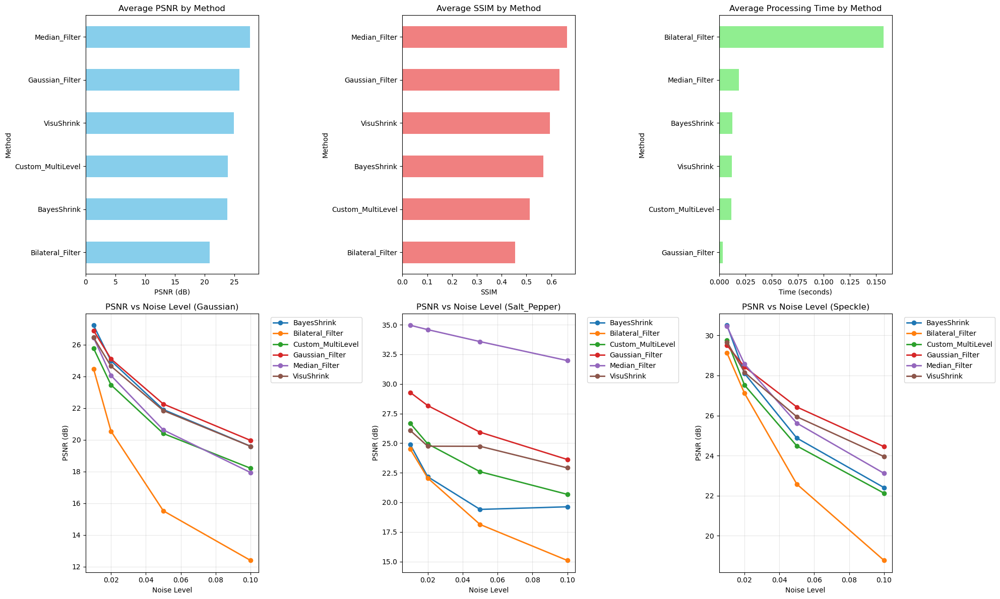

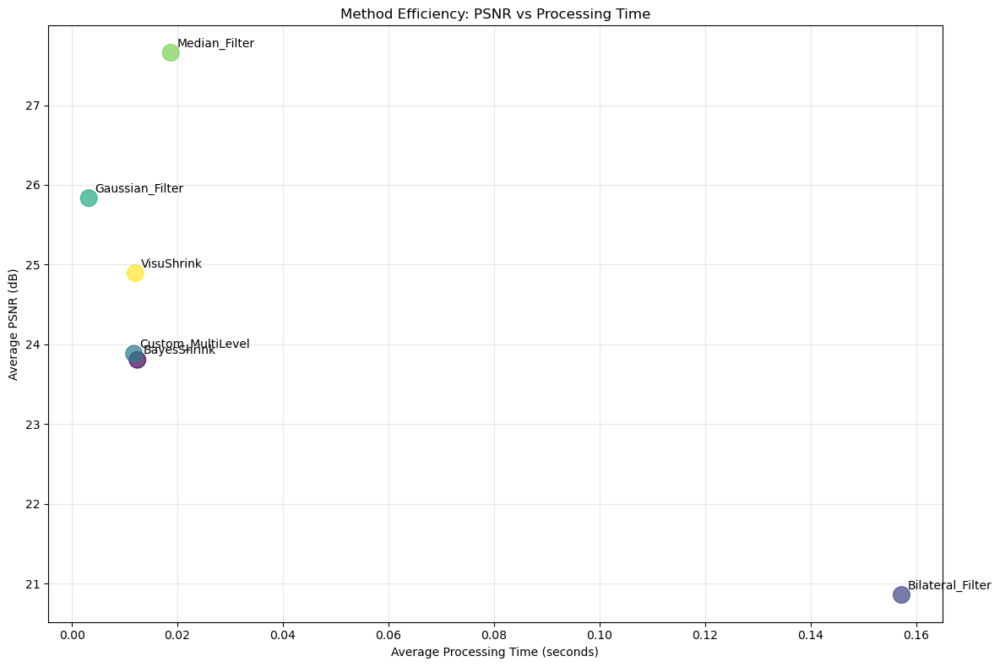


Detailed Performance Analysis:
Best method for gaussian noise: Gaussian_Filter (PSNR: 23.55 dB)
Best method for salt_pepper noise: Median_Filter (PSNR: 33.77 dB)
Best method for speckle noise: Gaussian_Filter (PSNR: 27.20 dB)

Most robust method: VisuShrink (PSNR std: 3.92)
Fastest method: Gaussian_Filter (0.0032 seconds)

Results saved to ./output/wavelet_benchmark_results.csv
Total tests completed: 360


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pywt
from skimage import data, img_as_float
from skimage.util import random_noise
from skimage.restoration import denoise_wavelet, denoise_bilateral
from skimage.filters import gaussian, median
from skimage.metrics import peak_signal_noise_ratio, structural_similarity
import time
import os

def comprehensive_evaluation_metrics(original, denoised, noisy):
    """Calculate comprehensive image quality metrics"""
    
    # Ensure images are in the same range
    original = np.clip(original, 0, 1)
    denoised = np.clip(denoised, 0, 1)
    noisy = np.clip(noisy, 0, 1)
    
    metrics = {}
    
    # PSNR
    metrics['PSNR'] = peak_signal_noise_ratio(original, denoised, data_range=1.0)
    
    # SSIM
    metrics['SSIM'] = structural_similarity(original, denoised, data_range=1.0)
    
    # Mean Squared Error
    metrics['MSE'] = np.mean((original - denoised) ** 2)
    
    # Mean Absolute Error
    metrics['MAE'] = np.mean(np.abs(original - denoised))
    
    # Improvement in SNR
    noise_power = np.mean((original - noisy) ** 2)
    residual_power = np.mean((original - denoised) ** 2)
    if noise_power > 0:
        metrics['SNR_Improvement'] = 10 * np.log10(noise_power / max(residual_power, 1e-10))
    else:
        metrics['SNR_Improvement'] = 0
    
    return metrics

class WaveletDenoisingBenchmark:
    """Comprehensive benchmarking suite for wavelet denoising methods"""
    
    def __init__(self):
        self.test_images = {}
        self.noise_types = ['gaussian', 'salt_pepper', 'speckle']
        self.noise_levels = [0.01, 0.02, 0.05, 0.1]
        self.methods = {
            'BayesShrink': lambda img: denoise_wavelet(img, method='BayesShrink', mode='soft', wavelet='db8'),
            'VisuShrink': lambda img: denoise_wavelet(img, method='VisuShrink', mode='soft', wavelet='db8'),
            'Custom_MultiLevel': self._custom_multilevel_denoise,
            'Gaussian_Filter': lambda img: gaussian(img, sigma=1.0),
            'Median_Filter': lambda img: median(img, footprint=np.ones((3, 3))),
            'Bilateral_Filter': lambda img: denoise_bilateral(img, sigma_color=0.1, sigma_spatial=1.5)
        }
        # Create random number generator for reproducible results
        self.rng = 42  # Use integer seed for newer scikit-image versions
        
    def _custom_multilevel_denoise(self, img):
        """Custom multi-level denoising implementation"""
        try:
            # Determine optimal decomposition level based on image size
            min_dim = min(img.shape)
            # Calculate maximum possible decomposition levels manually
            max_level = int(np.floor(np.log2(min_dim)))
            level = min(4, max_level)  # Use at most 4 levels or maximum possible
            
            coeffs = pywt.wavedec2(img, 'db8', level=level)
            
            # Estimate noise from finest detail coefficients
            sigma = np.std(coeffs[-1][-1]) / 0.6745  # Robust noise estimation
            
            coeffs_thresh = [coeffs[0]]
            for i, detail_coeffs in enumerate(coeffs[1:]):
                level_threshold = sigma * (1.2 - i * 0.15)
                thresh_details = tuple(pywt.threshold(detail, level_threshold, mode='soft') 
                                     for detail in detail_coeffs)
                coeffs_thresh.append(thresh_details)
            
            reconstructed = pywt.waverec2(coeffs_thresh, 'db8')
            
            # Handle potential size mismatch due to wavelet edge effects
            if reconstructed.shape != img.shape:
                # Crop or pad to match original size
                h_orig, w_orig = img.shape
                h_rec, w_rec = reconstructed.shape
                
                if h_rec >= h_orig and w_rec >= w_orig:
                    # Crop if reconstructed is larger
                    h_start = (h_rec - h_orig) // 2
                    w_start = (w_rec - w_orig) // 2
                    reconstructed = reconstructed[h_start:h_start+h_orig, w_start:w_start+w_orig]
                else:
                    # Pad if reconstructed is smaller
                    pad_h = max(0, h_orig - h_rec)
                    pad_w = max(0, w_orig - w_rec)
                    reconstructed = np.pad(reconstructed, 
                                         ((pad_h//2, pad_h - pad_h//2), 
                                          (pad_w//2, pad_w - pad_w//2)), 
                                         mode='edge')
            
            return np.clip(reconstructed, 0, 1)
            
        except Exception as e:
            # Fallback to simple denoising if wavelet method fails
            print(f"Wavelet denoising failed, using fallback: {str(e)}")
            return gaussian(img, sigma=1.0)
    
    def load_test_images(self):
        """Load diverse test images"""
        self.test_images = {
            'Natural_Scene': img_as_float(data.camera()),
            'Textured': img_as_float(data.brick()),
            'Smooth': img_as_float(data.moon()),
            'High_Contrast': img_as_float(data.coins()),
            'Structured': img_as_float(data.checkerboard())
        }
    
    def run_benchmark(self):
        """Run complete benchmark suite"""
        if not self.test_images:
            self.load_test_images()
        
        results = []
        
        print("Running Wavelet Denoising Benchmark...")
        print("=" * 50)
        
        total_tests = len(self.test_images) * len(self.noise_types) * len(self.noise_levels) * len(self.methods)
        test_count = 0
        
        for img_name, img in self.test_images.items():
            for noise_type in self.noise_types:
                for noise_level in self.noise_levels:
                    # Add noise with proper random number generator
                    if noise_type == 'gaussian':
                        noisy = random_noise(img, mode='gaussian', var=noise_level, rng=self.rng)
                    elif noise_type == 'salt_pepper':
                        noisy = random_noise(img, mode='s&p', amount=noise_level, rng=self.rng)
                    elif noise_type == 'speckle':
                        noisy = random_noise(img, mode='speckle', var=noise_level, rng=self.rng)
                    
                    for method_name, method_func in self.methods.items():
                        try:
                            # Apply denoising
                            start_time = time.time()
                            denoised = method_func(noisy)
                            processing_time = time.time() - start_time
                            
                            # Calculate metrics
                            metrics = comprehensive_evaluation_metrics(img, denoised, noisy)
                            metrics['Processing_Time'] = processing_time
                            
                            # Store result
                            result = {
                                'Image': img_name,
                                'Noise_Type': noise_type,
                                'Noise_Level': noise_level,
                                'Method': method_name,
                                **metrics
                            }
                            results.append(result)
                            
                        except Exception as e:
                            print(f"Error with {method_name} on {img_name}: {str(e)}")
                        
                        test_count += 1
                        if test_count % 10 == 0:
                            print(f"Progress: {test_count}/{total_tests} ({100*test_count/total_tests:.1f}%)")
        
        return pd.DataFrame(results)
    
    def analyze_results(self, results_df):
        """Analyze benchmark results and create visualizations"""
        
        # Create output directory if it doesn't exist
        os.makedirs('./output', exist_ok=True)
        
        # Overall method ranking
        method_ranking = results_df.groupby('Method')[['PSNR', 'SSIM', 'Processing_Time']].agg({
            'PSNR': 'mean',
            'SSIM': 'mean',
            'Processing_Time': 'mean'
        }).round(4)
        
        method_ranking = method_ranking.sort_values('PSNR', ascending=False)
        
        print("Overall Method Ranking (by average PSNR):")
        print("=" * 45)
        print(method_ranking.to_string())
        print()
        
        # Performance by noise type
        fig, axes = plt.subplots(2, 3, figsize=(20, 12))
        
        # PSNR by method
        method_psnr = results_df.groupby('Method')['PSNR'].mean().sort_values(ascending=True)
        method_psnr.plot(kind='barh', ax=axes[0, 0], color='skyblue')
        axes[0, 0].set_title('Average PSNR by Method')
        axes[0, 0].set_xlabel('PSNR (dB)')
        
        # SSIM by method
        method_ssim = results_df.groupby('Method')['SSIM'].mean().sort_values(ascending=True)
        method_ssim.plot(kind='barh', ax=axes[0, 1], color='lightcoral')
        axes[0, 1].set_title('Average SSIM by Method')
        axes[0, 1].set_xlabel('SSIM')
        
        # Processing time by method
        method_time = results_df.groupby('Method')['Processing_Time'].mean().sort_values(ascending=True)
        method_time.plot(kind='barh', ax=axes[0, 2], color='lightgreen')
        axes[0, 2].set_title('Average Processing Time by Method')
        axes[0, 2].set_xlabel('Time (seconds)')
        
        # Performance vs noise level
        for i, noise_type in enumerate(self.noise_types):
            if i < 3:
                noise_data = results_df[results_df['Noise_Type'] == noise_type]
                pivot_data = noise_data.pivot_table(values='PSNR', index='Noise_Level', columns='Method', aggfunc='mean')
                
                for method in pivot_data.columns:
                    axes[1, i].plot(pivot_data.index, pivot_data[method], 'o-', label=method, linewidth=2)
                
                axes[1, i].set_title(f'PSNR vs Noise Level ({noise_type.title()})')
                axes[1, i].set_xlabel('Noise Level')
                axes[1, i].set_ylabel('PSNR (dB)')
                axes[1, i].legend(bbox_to_anchor=(1.05, 1), loc='upper left')
                axes[1, i].grid(True, alpha=0.3)
        
        plt.tight_layout()
        plt.savefig('./output/13.20_wavelet_denoising_benchmark_analysis.png', dpi=300, bbox_inches='tight')
        plt.show()
        
        # Efficiency analysis (PSNR vs Processing Time)
        plt.figure(figsize=(12, 8))
        
        efficiency_data = results_df.groupby('Method')[['PSNR', 'Processing_Time']].mean()
        
        scatter = plt.scatter(efficiency_data['Processing_Time'], efficiency_data['PSNR'], 
                            s=200, alpha=0.7, c=range(len(efficiency_data)), cmap='viridis')
        
        for method, row in efficiency_data.iterrows():
            plt.annotate(method, (row['Processing_Time'], row['PSNR']), 
                        xytext=(5, 5), textcoords='offset points', fontsize=10)
        
        plt.xlabel('Average Processing Time (seconds)')
        plt.ylabel('Average PSNR (dB)')
        plt.title('Method Efficiency: PSNR vs Processing Time')
        plt.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.savefig('./output/wavelet_denoising_efficiency.png', dpi=300, bbox_inches='tight')
        plt.show()
        
        # Statistical analysis
        print("\nDetailed Performance Analysis:")
        print("=" * 50)
        
        # Best method for each noise type
        for noise_type in self.noise_types:
            noise_data = results_df[results_df['Noise_Type'] == noise_type]
            best_method = noise_data.groupby('Method')['PSNR'].mean().idxmax()
            best_psnr = noise_data.groupby('Method')['PSNR'].mean().max()
            print(f"Best method for {noise_type} noise: {best_method} (PSNR: {best_psnr:.2f} dB)")
        
        # Most robust method (lowest std deviation across all tests)
        method_robustness = results_df.groupby('Method')['PSNR'].std().sort_values()
        print(f"\nMost robust method: {method_robustness.index[0]} (PSNR std: {method_robustness.iloc[0]:.2f})")
        
        # Fastest method
        fastest_method = results_df.groupby('Method')['Processing_Time'].mean().idxmin()
        fastest_time = results_df.groupby('Method')['Processing_Time'].mean().min()
        print(f"Fastest method: {fastest_method} ({fastest_time:.4f} seconds)")
        
        return method_ranking

# Run benchmark
if __name__ == "__main__":
    benchmark = WaveletDenoisingBenchmark()
    benchmark_results = benchmark.run_benchmark()
    ranking = benchmark.analyze_results(benchmark_results)
    
    # Save results to CSV
    benchmark_results.to_csv('./output/13.21_wavelet_benchmark_results.csv', index=False)
    print(f"\nResults saved to ./output/wavelet_benchmark_results.csv")
    print(f"Total tests completed: {len(benchmark_results)}")